---
title: "Barkelew's runaway diagram"
description: "The 1959 chart that collapses the runaway boundary of a cooled tubular reactor onto two dimensionless groups - rebuilt from the paper that reprints it, and tested where a similarity reduction is supposed to fail."
categories: [sec:D, struct:S2, tier:T0, data:tier6, phase:gas-solid]
date: 2026-08-01
---

# Barkelew's runaway diagram

**Catalog ID:** `D2.1` · **Structures:** `S2` (plug flow with reaction) · **Tier:** T0

A cooled tubular reactor runs away when the heat it makes outruns the heat the
wall can take. Barkelew integrated that problem a great many times and found
that the boundary between safe and unsafe operation collapses onto **two
dimensionless groups**, so that one chart covers every first-order exothermic
reaction. This page rebuilds the chart, and then asks the question a collapse
always invites: how well does it actually collapse?

In [1]:
# Bootstrap: the pymrm this page was checked with, and the gallery files it was
# published with. Works in a checkout, in CI and on a fresh Colab VM.
GALLERY_REF = "main"  # replaced by the release tag at publication
PYMRM = ">=3.3.0,<4"  # equals meta.yaml pymrm_min_version, up to the next major
PAGE = "D2.1-barkelew-runaway-diagram"  # equals the page directory

import os, sys, urllib.request
from pathlib import Path
_shared = next((p / "shared" for p in (Path.cwd(), *Path.cwd().parents)
                if (p / "shared" / "gallery_bootstrap.py").is_file()), None)
if _shared is None:
    _shared = (Path(os.environ.get("XDG_CACHE_HOME") or Path.home() / ".cache")
               / "pymrm-gallery" / GALLERY_REF)
    _shared.mkdir(parents=True, exist_ok=True)
    urllib.request.urlretrieve(
        "https://raw.githubusercontent.com/computational-chemical-engineering/"
        f"pymrm-gallery/{GALLERY_REF}/shared/gallery_bootstrap.py",
        _shared / "gallery_bootstrap.py")
sys.path.insert(0, str(_shared))
sys.modules.pop("gallery_bootstrap", None)
from gallery_bootstrap import setup
setup(PAGE, PYMRM, GALLERY_REF);  # the semicolon stops the cell echoing the path

In [2]:
from dataclasses import replace
from functools import lru_cache

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display
from scipy.interpolate import PchipInterpolator
from scipy.optimize import brentq
from pymrm import NewtonBreakdown
from gallery_utils import load_data, load_meta, cite_data, Claims
from model import (Case, kexp, t_max_peak, n_group, p0_of_s, tau_max_phase,
                   tau_max_pymrm, u_at_tau, tangency_at_h, tangency, s_crit_tangency,
                   s_crit_level, p0_crit_vwf,
                   Tube, profile_ivp, blowup_z, linearisations, TAU_CAP, H_TAN)

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
pd.set_option("display.width", 200)
claims = Claims(PAGE.split("-")[0])

## Background

[`D2.2`](../D2.2-van-welsenaere-froment-runaway/) is the other half of this
story. Van Welsenaere and Froment (1970) located the runaway boundary from
**intrinsic geometric features** of the trajectory in the $p$–$T$ plane, and
turned them into closed-form inequalities on the inlet conditions: explicit
formulae in dimensional variables, one reactor at a time.

Barkelew (1959) did the opposite. He integrated the reactor equations over a
large parameter range and *correlated* the results, choosing groups in which
the whole family of solutions falls onto one picture. There is no formula at
the end of it; there is a chart, and using it takes trial and error. What it
buys is generality: the same four curves serve any tube, any coolant
temperature, any first-order exothermic chemistry.

That difference, an explicit criterion against a similarity reduction, is why
this is a separate page and not a section of `D2.2`. A collapse is a claim that
a two-parameter family really is two-parameter, and claims like that are
testable, including where they fail. `D2.2` has no such claim to test.

**Terminology, as both papers are careful about it.** With gas and solid at the
same temperature the ideal tubular reactor is an initial-value problem along
the tube, so its differential equations have one solution for each inlet state:
there is no bifurcation and no multiplicity here, unlike
[`B1.1`](../B1.1-thiele-weisz-hicks/). "Runaway" means *parametric
sensitivity*: a region where a small change in an inlet variable moves the hot
spot by hundreds of kelvin. (That uniqueness is a property of the differential
problem. The discretised reactor solved below is checked against an independent
quadrature and under grid refinement, not for uniqueness of its roots.)

## The published model

### Where this comes from, and where it does not

**Barkelew's paper was not consulted.** *Chem. Engng Prog. Symp. Ser.* 55 (1959)
37 is pre-DOI, is not on disk, and has no open-access route. Everything on this
page is read from **Van Welsenaere & Froment (1970)**, whose Section 5 is
explicitly a comparison with Barkelew: it reprints his diagram as their Fig. 9,
says what his axes mean, states the one numerical property of his critical
locus, and applies their own criterion in his notation. That is the reprint
route this repository uses for `F1.3` and `B1.6`, and the distinction is kept in
the metadata: `reference` is Barkelew, `reference_read_from` is Van Welsenaere &
Froment.

The consequence matters for reading this page. **Everything below is Barkelew's
method as Van Welsenaere and Froment describe and use it.** Where his own paper
would have given definitions, theirs gives sentences, and the reconstruction of
his groups from those sentences is set out explicitly so that it can be checked
rather than believed.

### The reactor

The starting point is the same model as `D2.2`, their Eqs. 3–4. One dimension,
pseudo-homogeneous, constant wall temperature, one irreversible pseudo-first-order
reaction:

$$
\frac{\mathrm{d}p}{\mathrm{d}z} = -A\,p\,\mathrm{e}^{-a/T+b},
\qquad
\frac{\mathrm{d}T}{\mathrm{d}z} = B\,p\,\mathrm{e}^{-a/T+b} - C\,(T-T_w),
$$

$$
A = \frac{M P \rho_b}{\rho_g} p_B^0, \qquad
B = \frac{(-\Delta H)\rho_b}{c_p} p_B^0, \qquad
C = \frac{2U}{c_p R}, \qquad z = \frac{z'}{u},
$$

with $p = p^0$, $T = T_0 = T_w$ at $z = 0$. The axial coordinate is a contact
time, not a length.

### Barkelew's simplification

Van Welsenaere and Froment write that Barkelew *"modified the temperature
dependence of the rate coefficient in such way that it may be characterized by
only one constant instead of two"*. The two constants are $a$ and $b$; the
modification that removes one of them is the exponential approximation to the
Arrhenius factor about the wall temperature,

$$
\mathrm{e}^{-a/T+b} \;\longrightarrow\; k_w\,\mathrm{e}^{\tau},
\qquad
k_w = \mathrm{e}^{-a/T_w+b},
\qquad
\boxed{\;\tau = \frac{a\,(T-T_w)}{T_w^{2}}\;}
$$

which is what makes $\tau$ the dimensionless temperature on the axes of his
diagram.

### What is forced by the printed text, and what is not

Section 5 gives $\tau$ a name and uses it, but never writes it down, so the
boxed definition is a **reconstruction**. Most of it is forced by what is
printed. One step is not, and the page says which is which rather than calling
the whole thing pinned.

**Forced: the shape of the reduced system, and the reference temperature.**
The two sentences Section 5 gives in words are

> *"$N/S$ is the ratio of the rate of heat transfer per unit volume at $\tau = 1$
> to the rate of heat generation per unit volume at $\tau = 0$. The parameter $S$
> corresponds to the value $\tau$ would reach if the reactants were fed at the
> wall temperature and if the reactor were operated adiabatically."*

The first fixes the cooling term as $N\tau$ and the generation as
$S\,y\,\mathrm{e}^{\tau}$ (at $\tau = 1$ the transfer rate is $N$, at $\tau=0$
with $y=1$ the generation rate is $S$), and a cooling term proportional to
$\tau$ forces $\tau \propto (T - T_w)$ with $\tau(T_w) = 0$. The second, and
only the second, names the wall temperature explicitly: it feeds the reactants
at it, so with $N = 0$ and $\mathrm{d}\tau/\mathrm{d}y = -S$ the adiabatic
$\tau$ is $S$ itself, and their own Eq. 32 turns that into
$S = a(\Delta T)_{ad}/T_w^2$.

**Forced too, by a third printed statement, is that the exponent is $\tau$ and
not a multiple of it.** Section 5 states that their own first criterion becomes
$\tau_m = 1$ in these variables. With a rate $\propto \mathrm{e}^{\lambda\tau}$
the maxima curve is $y \propto \tau\,\mathrm{e}^{-\lambda\tau}$ and its peak
sits at $\tau = 1/\lambda$, so their printed $\tau_m = 1$ forces $\lambda = 1$.

**Not forced: the temperature at which the exponent is linearised.** Nothing in
the paper says it. $a(T-T_w)/T_w^2$ is the tangent to $\ln k$ at the wall, but
the tangent at their own critical hot spot, $a(T-T_w)/T_M^2$, and the chord
between the two, $a(T-T_w)/(T_w T_M)$, satisfy every sentence quoted above
equally well: all three vanish at $T_w$, all three are linear in $T - T_w$, and
each comes with its own consistent $k_w$. That is a Frank–Kamenetskii
convention, not a constraint from the paper.

It is, however, **testable**, and this page tests it twice: once as a
deliberate defect in the break table, and once against the blow-up positions of
their Fig. 10. The wall tangent wins both times.

Substituting and rescaling the contact time by $\zeta = A k_w z$ leaves **two
parameters and nothing else**:

$$
\frac{\mathrm{d}y}{\mathrm{d}\zeta} = -y\,\mathrm{e}^{\tau},
\qquad
\frac{\mathrm{d}\tau}{\mathrm{d}\zeta} = S\,y\,\mathrm{e}^{\tau} - N\,\tau,
\qquad
y(0)=1,\; \tau(0)=0,
$$

with $y = p/p^0$ and

$$
S = \frac{a\,(\Delta T)_{ad}}{T_w^{2}} = \frac{a\,B\,p^0}{A\,T_w^{2}},
\qquad
N = \frac{C}{A\,k_w}.
$$

$N/S = C T_w^2 / (a B p^0 k_w)$ is exactly the ratio of the two rates their first
sentence describes. Note what has happened to the inlet pressure: $S \propto p^0$
and $N$ does not contain $p^0$ at all.

### The criterion

Barkelew plots $\tau_m/S$ against $N/S$ at constant $S$, where $\tau_m$ is the
hot spot. Section 5:

> *"The curves of constant $S$ have an envelope. Above the tangent to the
> envelope $\tau_m$ changes rapidly with $N/S$. Below that point it does not.
> The points of tangency therefore correspond to critical conditions."*

So the criterion is geometric: on each $S$-curve, the point where it touches the
envelope of the whole family. And then the one number Section 5 prints:

> *"It was observed that for all $S$-values $\tau_m$ at the point of tangency was
> very close to $1{\cdot}275$."*

That is the claim this page is built to test, and it is a **similarity claim**:
a statement that one number characterises the critical condition for every $S$.

### Where the two papers meet

Section 5 also carries Van Welsenaere and Froment's own criterion into
Barkelew's variables. Their first criterion puts the critical trajectory through
the maximum of the maxima curve; with the exponential rate law the maxima curve
is $y_m \propto \tau\,\mathrm{e}^{-\tau}$, whose peak is at $\tau = 1$ for any
choice of reference temperature. Hence:

> *"With Barkelew's dimensionless notation the first criterion leads to
> $\tau_m = 1$, so that $\tau_m/S = 1/S$. As indicated in Fig. 9 the corresponding
> point on each $S$-curve lies a bit to the right of the points of tangency
> between the $S$-curve and the envelope. Consequently, the first criterion
> proposed in this paper is slightly more conservative than Barkelew's."*

Two testable statements: the ordering (right of, for every $S$), and, through
Fig. 8, where they mark Barkelew's predictions against their own, that
*"Barkelew's predictions agree extremely well with these based upon the present
methods"*. Their Fig. 8 shows that comparison as marker positions only, so this
page does not read it; it recomputes **both** sides.

## Parameters and assumptions

The dimensionless system needs no parameters at all; that is the point of it.
Parameters enter only where the page leaves the diagram and asks what
Barkelew's criterion predicts for a specific tube, which is where it can be
compared with `D2.2`. For that the base case of their Section 1 is used
unchanged (loaded in the next section).

**Assumptions carried, all of them the papers'.** Plug flow; no axial
dispersion of heat or mass; constant wall temperature; constant physical
properties; one irreversible reaction, first order in the limiting reactant with
the second reactant in large excess; gas and solid at the same temperature. On
top of these, Barkelew's own: the Arrhenius factor replaced by an exponential in
$\tau$, which is accurate near $T_w$ and increasingly wrong above it, and
wrong in the unsafe direction, as the results below show.

**One trap in getting the numbers out**, inherited from `D2.2`. This is a 1970
scan and the Elsevier full-text API returns the publisher's OCR of it, which
discards the mid-dot decimal separator: `1275` for 1.275, `001651` for 0.01651,
`19837` for 19.837. The API is excellent for prose (it is how Section 5 was
located and read) and useless for numbers. Every number here was read from a
600 dpi render of the printed page.

The numerical choices of the page are set in the next cell.

In [3]:
N_ZETA = 1600                      # cells of the pymrm reduced tube (first-order upwind)
N_ZETA_STUDY = (200, 400, 800, 1600)   # grid study of the pymrm reduced tube
N_TUBE = 2000                      # cells of the pymrm dimensional tube
N_TUBE_STUDY = (2000, 4000, 8000, 16000)
H_STUDY = (0.04, 0.02, 0.01, 0.005, 0.0025)   # steps in ln S for the tangency
S_WIDE = [3., 4., 6., 8., 12., 16., 24., 32., 48., 64., 100., 150., 200.]
TW_GRID = np.arange(600.0, 701.0, 5.0)         # wall temperatures, K
print(f"tangency: Richardson pair (h, h/2) with h = {H_TAN}; quadrature capped at "
      f"tau = {TAU_CAP:g}")

tangency: Richardson pair (h, h/2) with h = 0.01; quadrature capped at tau = 20


## The data

Two files. The **parameters** are the base case of Section 1, needed only for
the dimensional comparison. The **Barkelew file** is everything Section 5 prints
about the diagram, plus the Section 6 values used to prove the parameter reading
is right.

**These are not measurements.** Barkelew's chart correlates his own numerical
integrations; Van Welsenaere and Froment's numbers are their own closed-form
extrapolations and Runge–Kutta runs. Neither paper contains an experiment, so
this page is provenance tier 6, validated against a published reference
solution in the same sense as [`B1.1`](../B1.1-thiele-weisz-hicks/) and
[`D2.2`](../D2.2-van-welsenaere-froment-runaway/), and not against experiment.

**No curve was digitised into these files.** The `label` and `axis` rows below
are text printed inside the figure frames. The markers on Fig. 9 (the crosses
at the tangency points and the circles at $\tau_m/S = 1/S$) were deliberately
not measured: that would be a figure digitisation, and the printed 1.275 makes
it unnecessary. Four positions *were* measured off Fig. 10, for the one question
nothing printed can settle; they are quarantined in their own cell near the end
of the page, they are not in either CSV, and they are awaiting a maintainer's
visual review.

In [4]:
par = load_data("van-welsenaere-froment-1970-parameters.csv", page=PAGE)
bk = load_data("van-welsenaere-froment-1970-barkelew.csv", page=PAGE)
bk_meta = load_meta("van-welsenaere-froment-1970-barkelew.csv", page=PAGE)

CASE = Case.from_table(zip(par.symbol, par.value))
V = dict(zip(bk.quantity, bk.value))
S_PRINTED = [V["S_curve_1"], V["S_curve_2"], V["S_curve_3"], V["S_curve_4"]]
TAU_STATED = V["tau_m_at_tangency"]

print(par.to_string(index=False) + "\n\n"
      + bk[["quantity", "value", "unit", "kind", "source"]].to_string(index=False)
      + f"\n\n{cite_data(bk_meta)}\n"
      + "origin of the result (not consulted): "
      + " ".join(f"{bk_meta['reprint_of']['authors'][0]} "
                 f"({bk_meta['reprint_of']['year']}), "
                 f"{bk_meta['reprint_of']['container']}".split())
      + f"\nprovenance tier {bk_meta['provenance_tier']['tier']}")

  symbol       value              unit                                         description
       M     29.4800           kg/kmol                               mean molecular weight
       P      1.0000               atm                                      total pressure
   rho_b   1300.0000             kg/m3                               catalyst bulk density
   rho_g      1.2930             kg/m3                                         gas density
minus_dH 307000.0000         kcal/kmol                                    heat of reaction
     c_p      0.3230    kcal/(m3 degC)                 volumetric heat capacity of the gas
       u   3600.0000              m/hr                                superficial velocity
       U     82.7000 kcal/(m2 hr degC)              overall wall heat transfer coefficient
       R      0.0125                 m                             tube radius (base case)
    p_B0      0.2080               atm partial pressure of the second reactant (in excess)

In [5]:
def parameter_reading(case):
    """Four derived quantities the paper prints, recomputed from the parameter table.

    They were not used to obtain the table, so a lost decimal point anywhere in
    it, or the c_p x rho_g trap, shows here.
    """
    rows = [
        ("t_w  (Eq. 21b)", case.a / 625.0, V["t_w_at_Tw625"]),
        ("ln K (Eq. 22)", float(np.log(case.A / case.C * np.exp(case.b - 20.0))),
         V["lnK_at_Tw625"]),
        ("T_M  (Eq. 8), K", float(t_max_peak(case, 625.0)), V["T_M_at_Tw625"]),
        ("(dT)_ad (Eq. 32) at p0=0.0125 atm, K", case.B / case.A * 0.0125,
         V["dT_ad_at_p0_0125"]),
    ]
    df = pd.DataFrame(rows, columns=["quantity", "recomputed", "printed"])
    df["dev %"] = (df.recomputed - df.printed).abs() / df.printed.abs() * 100
    return df


CHK5 = parameter_reading(CASE)
print("The parameter reading, against four numbers the paper prints and that\n"
      "were not used to obtain it (a single lost decimal breaks all four):\n"
      + CHK5.to_string(index=False, float_format=lambda v: f"{v:.4f}"))

The parameter reading, against four numbers the paper prints and that
were not used to obtain it (a single lost decimal breaks all four):
                            quantity  recomputed  printed  dev %
                      t_w  (Eq. 21b)     21.8176  21.8180 0.0018
                       ln K (Eq. 22)     -2.0568  -2.0550 0.0899
                     T_M  (Eq. 8), K    656.6183 656.6000 0.0028
(dT)_ad (Eq. 32) at p0=0.0125 atm, K    521.0950 521.0900 0.0010


## PyMRM implementation

Three pieces, kept separate because they fail independently; all three live in
`model.py`.

1. **The dimensionless Barkelew tube**, `BarkelewTube`, solved with pymrm.
   Convection in $\zeta$ with a pointwise source (`construct_convflux_upwind`
   then `construct_div`, the same two calls as `D2.2` and
   [`C2.1`](../C2.1-xu-froment-smr/)), state $(y, \tau)$ of shape
   $(n_\zeta, 2)$, the source differentiated per cell by `NumJac`, and
   `pymrm.newton` with a step tolerance of 1e-10 on unknowns of order one. A
   solve that does not converge raises; it is never read as a result. This
   route is the cross-check.
2. **The same system in the phase plane**, $\mathrm{d}\tau/\mathrm{d}y$, solved
   by adaptive quadrature (`tau_max_phase`). It never forms a grid, and its
   right-hand side is a **separate transcription** of the reduced model, not a
   call into the finite-volume one. It is cheap and accurate, so it draws the
   diagram, and the pymrm discretisation is measured against it.
3. **The dimensional tube**, `Tube`, with the true Arrhenius factor or
   Barkelew's exponential, for the comparison of their Fig. 3 with their
   Fig. 10, solved with bounds $T > 0$ where the Arrhenius factor is defined.

Four implementation choices are worth stating.

*The domain of the pymrm tube is chosen, not fixed.* The hot spot sits near
$\zeta \approx 0.5$ for $S = 4$ and $\zeta \approx 0.1$ for $S = 32$, so one
fixed domain either misses the peak or wastes its cells on the tail. A cheap
200-cell solve locates the peak, the fine solve then covers three times that.
This is arithmetic on the grid, not a continuation: nothing is warm-started and
the answer does not depend on the order the cases are solved in.

*The quadrature is capped at $\tau = 20$.* Deep inside the runaway region
$\tau_m \to S$ and $\mathrm{e}^{\tau}$ overflows for the larger $S$. Every
$\tau$ this page reports is below 13, so the cap only makes the useless region
cheap; where it binds, the value returned is the cap and is never used as a
result.

*Root-finds are bracketed and the bracket is tested.* The tangency search is
bracketed by the two hot spots $\tau_m = 1.7$ and $\tau_m = 0.7$, chosen to
straddle it without reference to the paper's 1.275, and `brentq` is given a sign
change it has verified. No parameter walk enters any reported number: every
threshold on the page is a root of a function whose every evaluation is an
independent quadrature. That includes the critical $S$ for a given $N$, which is
solved for in $\ln S$ at each wall temperature; the interpolant through the
table of tangencies only draws the envelope and gives each root its first
bracket. That is also why `pymrm.continuation` and
`pymrm.pseudo_transient` have no place here: there is no branch to follow and no
steady state that a cold Newton start misses; the only thing located is a level
crossing or a sign change of a difference, which is a scalar root.

*The tangency itself has a step size, and it is converged rather than chosen.*
The envelope is located from a difference of $\tau_m/S$ in $\ln S$ over a step
$h$; that difference has an $O(h^2)$ truncation error, so the raw value at any
fixed $h$ is biased. The pair $(h, h/2)$ is Richardson-extrapolated, and the
next section measures what that is worth. The extrapolated value is a pure
function of $S$, so it is memoised: arithmetic reuse, not a warm start.

In [6]:
def peak_position(S):
    """zeta of the pymrm hot spot at the tangency of the curve S."""
    _, tube = tau_max_pymrm(tangency(S)[0] * S, S, n_z=N_ZETA, return_tube=True)
    return float(tube.z_c[np.argmax(tube.u[:, 1])])


ZETA_PEAK = {S: peak_position(S) for S in (S_PRINTED[0], S_PRINTED[-1])}
print("the four curves Barkelew's diagram is drawn with:", S_PRINTED)
print("pymrm hot spot position at the tangency: "
      + ", ".join(f"zeta = {z:.3f} at S = {S:.0f}" for S, z in ZETA_PEAK.items()))

the four curves Barkelew's diagram is drawn with: [4.0, 8.0, 16.0, 32.0]
pymrm hot spot position at the tangency: zeta = 0.461 at S = 4, zeta = 0.108 at S = 32


## Results

### First: the step size the whole page rests on

Every number below is a tangency, and a tangency is located from a finite
difference. Before quoting any of them to four figures, here is what the step
size does. The table gives $\tau_m$ at the tangency at five step sizes and the
two Richardson extrapolations that can be formed from the last three.

In [7]:
def step_study(Ss=S_PRINTED + [200.0], hs=H_STUDY, tm=tau_max_phase):
    """tau_m at the tangency for every (S, h), and the two Richardson estimates."""
    raw = {S: {h: tangency_at_h(S, tm, h=h)[1] for h in hs} for S in Ss}
    rich1 = {S: (4 * raw[S][0.005] - raw[S][0.01]) / 3 for S in Ss}
    rich2 = {S: (4 * raw[S][0.0025] - raw[S][0.005]) / 3 for S in Ss}
    return raw, rich1, rich2


def truncation_order(raw, ref, hs=H_STUDY):
    """Slope of the mean relative error against h, on log axes."""
    err = np.array([[abs(raw[S][h] - ref[S]) / ref[S] for h in hs] for S in ref])
    return float(np.polyfit(np.log(hs), np.log(err.mean(axis=0)), 1)[0])


def drift(values):
    """Fall of tau_m from S = 4 to S = 200, % of the S = 4 value."""
    return (values[200.0] - values[S_PRINTED[0]]) / values[S_PRINTED[0]] * 100


RAW, RICH1, RICH2 = step_study()
CONV = RICH2
step = pd.DataFrame({"S": list(RAW)})
for h in H_STUDY:
    step[f"h={h:g}"] = [RAW[S][h] for S in RAW]
step["Richardson(.01,.005)"] = [RICH1[S] for S in RAW]
step["Richardson(.005,.0025)"] = [RICH2[S] for S in RAW]
step["error at h=0.04, %"] = [(RAW[S][0.04] - CONV[S]) / CONV[S] * 100 for S in RAW]
ORDER_H = truncation_order(RAW, CONV)
RICH_GAP = max(abs(RICH2[S] - RICH1[S]) / CONV[S] * 100 for S in RAW)
MAD_H004 = np.mean([abs(RAW[S][0.04] - TAU_STATED) / TAU_STATED * 100 for S in S_PRINTED])
MAD_CONV = np.mean([abs(CONV[S] - TAU_STATED) / TAU_STATED * 100 for S in S_PRINTED])
DRIFT_H004 = drift({S: RAW[S][0.04] for S in RAW})
DRIFT_CONV = drift(CONV)
INFLATION = abs(DRIFT_H004 - DRIFT_CONV)
BIAS_S4 = step["error at h=0.04, %"].iloc[0]
BIAS_S200 = step["error at h=0.04, %"].iloc[-1]
print("tau_m at the envelope tangency, against the step size h in ln S\n"
      + step.to_string(index=False, float_format=lambda v: f"{v:9.6f}")
      + f"\n\nobserved order of the truncation error: {ORDER_H:.2f}  (O(h^2) expected)"
      + "\nthe two Richardson estimates differ by below 1e-4 % of the value "
      + f"(here {RICH_GAP:.1e} %),"
      + "\nso the extrapolated tangency is converged well past the four figures quoted."
      + f"\n\nmean |dev| from {TAU_STATED} over the four S-curves Barkelew drew:"
      + f"\n  at h = 0.04 (a plausible fixed choice) : {MAD_H004:.3f} %"
      + f"\n  extrapolated to h -> 0                 : {MAD_CONV:.3f} %"
      + f"\nthe fall in tau_m from S = {S_PRINTED[0]:.0f} to S = 200, this page's main result:"
      + f"\n  at h = 0.04                            : {DRIFT_H004:+.3f} %"
      + f"\n  extrapolated to h -> 0                 : {DRIFT_CONV:+.3f} %"
      + f"\n  so a fixed h = 0.04 INFLATES the drift by {INFLATION:.3f} points, "
      + f"{INFLATION / abs(DRIFT_CONV) * 100:.0f} % of it.")

tau_m at the envelope tangency, against the step size h in ln S
         S    h=0.04    h=0.02    h=0.01   h=0.005  h=0.0025  Richardson(.01,.005)  Richardson(.005,.0025)  error at h=0.04, %
  4.000000  1.286800  1.287634  1.287843  1.287895  1.287908              1.287913                1.287912           -0.086383
  8.000000  1.274583  1.275904  1.276235  1.276318  1.276339              1.276345                1.276345           -0.138086
 16.000000  1.252101  1.254026  1.254509  1.254630  1.254660              1.254670                1.254670           -0.204735
 32.000000  1.225710  1.228388  1.229063  1.229232  1.229274              1.229288                1.229288           -0.291089
200.000000  1.154550  1.160199  1.161670  1.162042  1.162135              1.162166                1.162166           -0.655333

observed order of the truncation error: 1.99  (O(h^2) expected)
the two Richardson estimates differ by below 1e-4 % of the value (here 2.8e-05 %),
so the extrapolated tangen

Two things to take from that table, and the second is the
reason it is printed at all.

The truncation error is $O(h^2)$ as advertised, and the pair
$(h, h/2) = (0.01, 0.005)$ extrapolates to a value that a second pair
$(0.005, 0.0025)$ confirms to far better than the digits quoted. **Every
$\tau_m$ from here on is that extrapolated value**, so the tangency is reported
as the exactly defined mathematical object it is, not as an artefact of a step
size nobody varied.

And the bias is **not** neutral with respect to what this page concludes. It
grows monotonically with $S$, from 0.09 % at $S = 4$ to 0.66 % at $S = 200$,
which is the *same direction* as the drift in $\tau_m$ that is this page's main
new result. An unconverged step would therefore have inflated the conclusion:
at $h = 0.04$ the fall from $S = 4$ to $S = 200$ reads 0.5 percentage points
steeper than it is, 5 % of the drift. The drift survives convergence, but a page
that had not checked would not have known that.

### The diagram

Their Fig. 9, recomputed: $\tau_m/S$ against $N/S$ for the four printed
$S$-values, over the printed axis ranges. The **envelope** and the tangency
points are computed, not read; the open circles are Van Welsenaere and
Froment's own first criterion in these coordinates, $\tau_m/S = 1/S$.

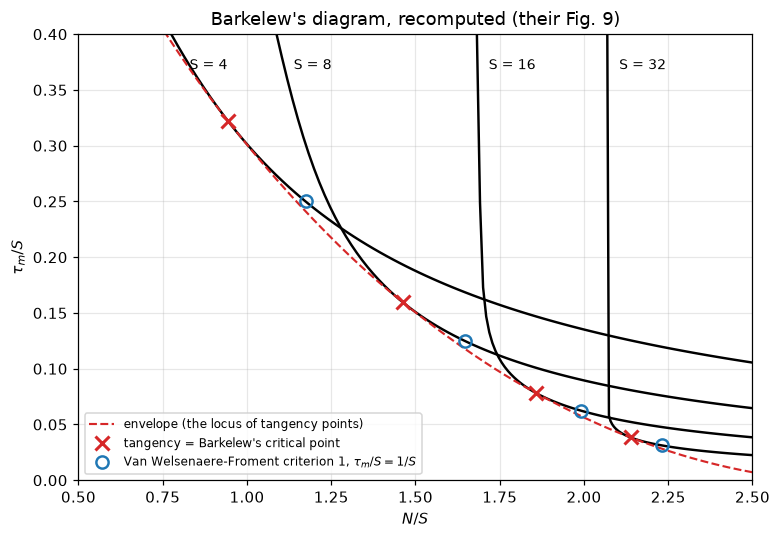

largest tau_m drawn on the diagram: 12.80


In [8]:
# tangency and the tau_m = 1 point, on every S
TAN_U, TAN_T, ONE_U = {}, {}, {}
for S in S_WIDE:
    TAN_U[S], TAN_T[S] = tangency(S)
    ONE_U[S] = u_at_tau(S, 1.0)

NS_MIN, NS_MAX = V["fig9_NS_min"], V["fig9_NS_max"]


def s_curves(ts_max, Ss=S_PRINTED):
    """The S-curves of Fig. 9 over the printed abscissa, up to tau_m/S = ts_max."""
    out = {}
    for S in Ss:
        u_lo = max(NS_MIN, u_at_tau(S, ts_max * S) if ts_max * S < TAU_CAP else NS_MIN)
        uu = np.linspace(u_lo, NS_MAX, 90)
        out[S] = (uu, np.array([tau_max_phase(u * S, S) for u in uu]) / S)
    return out


CURVES = s_curves(V["fig9_tauS_max"])
TAU_DRAWN_MAX = max(float((vv * S).max()) for S, (uu, vv) in CURVES.items())

# The envelope IS the locus of tangency points: each S-curve touches it exactly
# where d/dS vanishes, so no separate construction is needed, and a pointwise
# minimum over a truncated S-range would be an artefact of where it was
# truncated, not the envelope.
env_u = np.array([TAN_U[S] for S in S_WIDE])
env_v = np.array([TAN_T[S] / S for S in S_WIDE])
env_spline = PchipInterpolator(env_u, env_v)
env_uu = np.linspace(env_u.min(), min(env_u.max(), NS_MAX), 300)

fig, ax = plt.subplots(figsize=(7.2, 5.0))
for S, (uu, vv) in CURVES.items():
    ax.plot(uu, vv, "k-", lw=1.6)
    j = int(np.argmin(np.abs(vv - 0.385)))
    ax.text(uu[j] + 0.035, 0.378, f"S = {S:.0f}", fontsize=9, va="top", ha="left")
ax.plot(env_uu, env_spline(env_uu), "--", color="tab:red", lw=1.4,
        label="envelope (the locus of tangency points)")
ax.plot([TAN_U[S] for S in S_PRINTED], [TAN_T[S] / S for S in S_PRINTED],
        "x", color="tab:red", ms=9, mew=2, label="tangency = Barkelew's critical point")
ax.plot([ONE_U[S] for S in S_PRINTED], [1.0 / S for S in S_PRINTED],
        "o", mfc="none", mec="tab:blue", ms=8, mew=1.6,
        label=r"Van Welsenaere-Froment criterion 1, $\tau_m/S = 1/S$")
ax.set(xlabel="$N/S$", ylabel=r"$\tau_m/S$", xlim=(NS_MIN, NS_MAX),
       ylim=(0.0, V["fig9_tauS_max"]), title="Barkelew's diagram, recomputed (their Fig. 9)")
ax.legend(fontsize=8, loc="lower left")
fig.tight_layout()
plt.show()
print(f"largest tau_m drawn on the diagram: {TAU_DRAWN_MAX:.2f}")

### Does it collapse?

The whole value of the chart is that the tangency points share one $\tau_m$. The
paper says 1.275, for all $S$. Here is $\tau_m$ at the tangency over
$S = 3$ to 200 instead of the 4 to 32 Barkelew drew, at the converged step
size.

In [9]:
def collapse_table(tan_u, tan_t, one_u, stated=TAU_STATED):
    tab = pd.DataFrame({
        "S": S_WIDE,
        "(N/S) tangency": [tan_u[S] for S in S_WIDE],
        "tau_m tangency": [tan_t[S] for S in S_WIDE],
        "dev from 1.275 %": [(tan_t[S] - stated) / stated * 100 for S in S_WIDE],
        "(N/S) at tau_m=1": [one_u[S] for S in S_WIDE],
        "gap to the right %": [(one_u[S] - tan_u[S]) / tan_u[S] * 100 for S in S_WIDE],
    })
    tab["drawn by Barkelew"] = ["yes" if S in S_PRINTED else "" for S in S_WIDE]
    return tab


TAB = collapse_table(TAN_U, TAN_T, ONE_U)
drawn = TAB[TAB["drawn by Barkelew"] == "yes"]
MAD_DRAWN = drawn["dev from 1.275 %"].abs().mean()
MAD_WIDE = TAB["dev from 1.275 %"].abs().mean()
PEAK_S = float(TAB.S[TAB["tau_m tangency"].idxmax()])
_t = TAB["tau_m tangency"].values
PEAK_MARGIN = float(np.min(_t.max() - np.delete(_t, np.argmax(_t))) / _t.max())
DROP_4_32 = TAN_T[S_PRINTED[0]] - TAN_T[S_PRINTED[-1]]
GAPS = TAB["gap to the right %"].values
print(TAB.to_string(index=False, float_format=lambda v: f"{v:8.4f}")
      + f"\n\nover the four S-curves Barkelew drew : mean |dev| {MAD_DRAWN:.3f} %, "
      + f"tau_m from {drawn['tau_m tangency'].min():.4f} to {drawn['tau_m tangency'].max():.4f}"
      + f"\nover S = {min(S_WIDE):.0f} to {max(S_WIDE):.0f}          : mean |dev| {MAD_WIDE:.3f} %, "
      + f"tau_m from {TAB['tau_m tangency'].min():.4f} to {TAB['tau_m tangency'].max():.4f}"
      + f"\nlargest tau_m at S = {PEAK_S:.0f}; it falls by {DROP_4_32:.4f} from S = 4 to S = 32"
      + f"\nthe gap is positive for {int((GAPS > 0).sum())} of the {len(TAB)} values of S"
      + f"   (range {GAPS.min():.1f} to {GAPS.max():.1f} %)")

       S  (N/S) tangency  tau_m tangency  dev from 1.275 %  (N/S) at tau_m=1  gap to the right % drawn by Barkelew
  3.0000          0.6985          1.2863            0.8837            0.9386             34.3665                  
  4.0000          0.9440          1.2879            1.0128            1.1738             24.3512               yes
  6.0000          1.2620          1.2830            0.6255            1.4664             16.1972                  
  8.0000          1.4625          1.2763            0.1055            1.6458             12.5345               yes
 12.0000          1.7077          1.2644           -0.8343            1.8612              8.9874                  
 16.0000          1.8563          1.2547           -1.5945            1.9899              7.1975               yes
 24.0000          2.0331          1.2400           -2.7418            2.1416              5.3339                  
 32.0000          2.1380          1.2293           -3.5852            2.2309    

$\tau_m$ at the tangency is not a constant. It is largest at
$S = 4$, at the very left edge of the range Barkelew drew, and falls
monotonically thereafter, so 1.275 is a good summary of his four curves and a
steadily worse one outside them. The panel below shows the drift, and shows how
far outside his range it has to be pushed before the collapse stops being
usable.

This is not a contradiction of anything the paper asserts. Section 5 says *"very
close to"*, which already declines to claim a constant, and the crosses printed
on their Fig. 9 could not have resolved a change of 0.06 in $\tau_m$ across
$S = 4$–32 anyway. What the computation supplies is the size of "very close to",
and the fact that it has a sign and a direction.

The second statement in Section 5 survives intact: the point $\tau_m/S = 1/S$
lies to the right of the tangency for **every** $S$ tested, so Van Welsenaere
and Froment's first criterion is more conservative than Barkelew's everywhere,
not merely on the four curves they could see. The size of that margin is not in
either paper: it shrinks from 24 % of $N/S$ at $S = 4$ to 1.2 % at
$S = 200$.

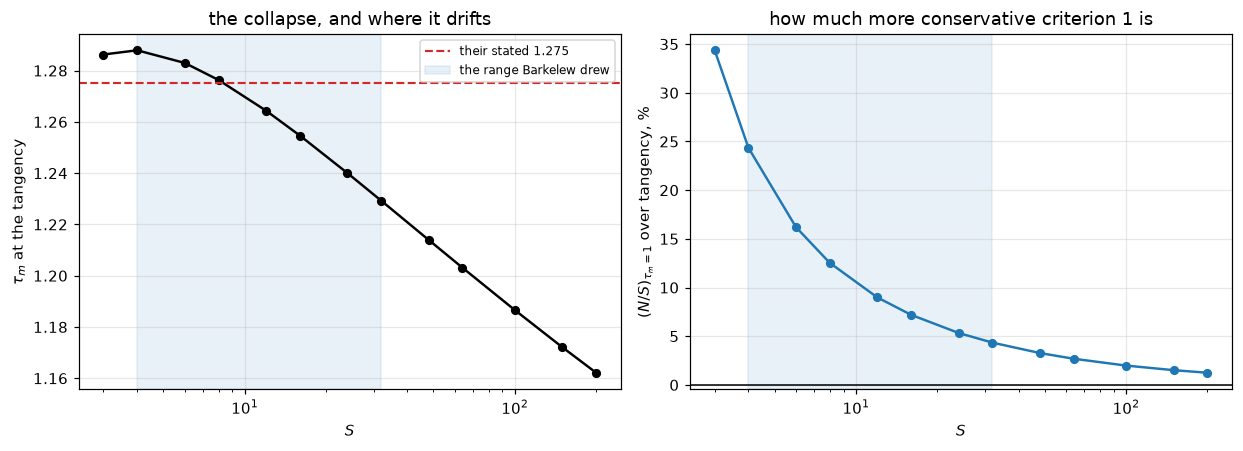

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(11.4, 4.2))
ax = axes[0]
ax.semilogx(TAB.S, TAB["tau_m tangency"], "o-", color="k", lw=1.6, ms=5)
ax.axhline(TAU_STATED, color="tab:red", ls="--", lw=1.4, label=f"their stated {TAU_STATED}")
ax.axvspan(min(S_PRINTED), max(S_PRINTED), color="tab:blue", alpha=0.10,
           label="the range Barkelew drew")
ax.set(xlabel="$S$", ylabel=r"$\tau_m$ at the tangency",
       title="the collapse, and where it drifts")
ax.legend(fontsize=8)

ax = axes[1]
ax.semilogx(TAB.S, TAB["gap to the right %"], "o-", color="tab:blue", lw=1.6, ms=5)
ax.axhline(0.0, color="k", lw=1.0)
ax.axvspan(min(S_PRINTED), max(S_PRINTED), color="tab:blue", alpha=0.10)
ax.set(xlabel="$S$", ylabel=r"$(N/S)_{\tau_m=1}$ over tangency, %",
       title="how much more conservative criterion 1 is")
fig.tight_layout()
plt.show()

### What the two criteria predict for a real tube

$N$ depends only on the wall temperature and the tube radius; $S$ carries the
inlet pressure. So Barkelew's criterion, read backwards, gives a critical inlet
pressure for any $T_w$, which is what the circled crosses on their Fig. 8 are.
The comparison below recomputes both sides: Barkelew's tangency locus with his
exponential rate law, against Van Welsenaere and Froment's first criterion
back-integrated with the **true** Arrhenius law, the quantity their Example 1
prints as 0.01651 atm.

In [11]:
# Interpolants over the 13 tangencies of the table: they draw the envelope and
# give each root-find its first bracket, and no published number is read off them.
_LOG_S = np.log(S_WIDE)
_S_OF_N = PchipInterpolator(np.log([TAN_U[S] * S for S in S_WIDE]), _LOG_S)
_S_OF_N_ONE = PchipInterpolator(np.log([ONE_U[S] * S for S in S_WIDE]), _LOG_S)
_U_OF_S = PchipInterpolator(_LOG_S, np.log([TAN_U[S] for S in S_WIDE]))


@lru_cache(maxsize=None)
def s_crit(N):
    """Barkelew's critical S at this N, by a direct root in ln S (model.s_crit_tangency)."""
    S0 = float(np.exp(_S_OF_N(np.log(N))))
    return s_crit_tangency(N, S0 * np.exp(-0.01), S0 * np.exp(0.01),
                           u_guess=lambda S: float(np.exp(_U_OF_S(np.log(S)))))


@lru_cache(maxsize=None)
def s_crit_one(N, level=1.0):
    """S at which tau_m = level at this N (criterion 1 for level 1), a direct root."""
    S0 = float(np.exp(_S_OF_N_ONE(np.log(N))))
    return s_crit_level(N, S0 * np.exp(-0.05), S0 * np.exp(0.05), target=level)


def critical_pressures(case=CASE, T2=None, kk=None, tws=TW_GRID, level=1.0, interp=False):
    """Critical inlet pressures over the wall temperatures, three ways.

    The critical S of both criteria is a direct root at each N. ``T2(Tw)`` is
    the squared reference temperature in tau = a (T - Tw)/T2 and ``kk(Tw)`` the
    rate coefficient at the wall under the same linearisation (default: the
    wall tangent); ``level`` places criterion 1 at tau_m = level. They exist
    for the break tables, as does ``interp=True``, which reads S off the table
    interpolants instead of solving for it.
    """
    T2 = (lambda Tw: Tw ** 2) if T2 is None else T2
    kk = (lambda Tw: float(kexp(case, Tw))) if kk is None else kk
    rows = []
    for Tw in tws:
        N = float(case.C / (case.A * kk(Tw)))
        if interp:
            Sb, S1 = (float(np.exp(f(np.log(N)))) for f in (_S_OF_N, _S_OF_N_ONE))
        else:
            Sb, S1 = s_crit(N), s_crit_one(N, level)
        p0 = lambda S: S * case.A * T2(Tw) / (case.a * case.B)
        rows.append((Tw, N, Sb, p0(Sb), p0(S1), p0_crit_vwf(case, Tw)))
    cmp = pd.DataFrame(rows, columns=["Tw", "N", "S_crit", "p0 Barkelew",
                                      "p0 crit-1 (exp law)", "p0 VWF exact (true law)"])
    cmp["dev Barkelew vs VWF %"] = ((cmp["p0 Barkelew"] - cmp["p0 VWF exact (true law)"])
                                    / cmp["p0 VWF exact (true law)"] * 100)
    return cmp


def crossing(case=CASE):
    """Wall temperature at which Barkelew's and the true-law criterion 1 cross."""
    gap = lambda Tw: float(critical_pressures(case, tws=[Tw])["dev Barkelew vs VWF %"].iloc[0])
    return brentq(gap, 600.0, 700.0, xtol=1e-4), gap(600.0), gap(700.0)


CMP = critical_pressures()
I625 = int(np.argmin(np.abs(CMP.Tw.values - 625.0)))
P0_VWF_625 = CMP["p0 VWF exact (true law)"][I625]
P0_BK_625 = CMP["p0 Barkelew"][I625]
VWF_VS_PRINTED = abs(P0_VWF_625 - V["p0_crit_1_at_Tw625"]) / V["p0_crit_1_at_Tw625"] * 100
DEV_625 = CMP["dev Barkelew vs VWF %"][I625]
DEV_MEAN = CMP["dev Barkelew vs VWF %"].abs().mean()
DEV_WORST = CMP["dev Barkelew vs VWF %"].abs().max()
TW_CROSS, GAP_600, GAP_700 = crossing()
CMP_INTERP = critical_pressures(interp=True)
INTERP_GAP = float(((CMP_INTERP["p0 Barkelew"] - CMP["p0 Barkelew"]).abs()
                    / CMP["p0 Barkelew"]).max())
print(CMP[CMP.Tw.isin([600., 625., 650., 675., 700.])].to_string(
          index=False, float_format=lambda v: f"{v:10.5f}")
      + f"\n\nat Tw = 625 K, their Example 1 prints (p0)_cr,1 = {V['p0_crit_1_at_Tw625']} atm"
      + f"\n  this page's back-integration of the same criterion : {P0_VWF_625:.5f} atm  "
      + f"({VWF_VS_PRINTED:.3f} %)"
      + f"\n  Barkelew's criterion, recomputed                   : {P0_BK_625:.5f} atm  "
      + f"({DEV_625:+.2f} % against it)"
      + f"\n\nover Tw = 600-700 K: mean |dev| {DEV_MEAN:.3f} %, worst {DEV_WORST:.3f} %, "
      + f"signed range {CMP['dev Barkelew vs VWF %'].min():+.2f} to "
      + f"{CMP['dev Barkelew vs VWF %'].max():+.2f} %"
      + f"\nthe two methods cross at Tw = {TW_CROSS:.2f} K (bracketed: {GAP_600:+.2f} % "
      + f"at 600 K, {GAP_700:+.2f} % at 700 K)"
      + "\n\nThe critical S is a root at each N; read off the interpolant through the 13"
      + "\ntangencies instead (as the plots are drawn) it differs by below 2e-3 of p0 "
      + f"(here {INTERP_GAP:.1e}).")

        Tw          N     S_crit  p0 Barkelew  p0 crit-1 (exp law)  p0 VWF exact (true law)  dev Barkelew vs VWF %
 600.00000  119.52359   52.33538      0.03314              0.03224                  0.03395               -2.37806
 625.00000   48.15606   23.73644      0.01631              0.01559                  0.01651               -1.21010
 650.00000   20.80740   12.13909      0.00902              0.00843                  0.00899                0.36485
 675.00000    9.56708    6.98151      0.00560              0.00510                  0.00548                2.20525
 700.00000    4.64991    4.48304      0.00386              0.00343                  0.00371                4.05651

at Tw = 625 K, their Example 1 prints (p0)_cr,1 = 0.01651 atm
  this page's back-integration of the same criterion : 0.01651 atm  (0.005 %)
  Barkelew's criterion, recomputed                   : 0.01631 atm  (-1.21 % against it)

over Tw = 600-700 K: mean |dev| 1.767 %, worst 4.057 %, signed range -2.38 to +

#### The two approximations, separated

Section 5's comparison mixes two different things: Barkelew's *criterion* (the
envelope tangency instead of $\tau_m = 1$) and Barkelew's *rate law* (the
exponential instead of the true Arrhenius factor). Their Fig. 8 puts his values
next to theirs and the text says the two *"agree extremely well"*, but a reader
cannot tell how much of whatever difference remains is which. The paper does
say his values were obtained *"using the modified rate equation"*, so it is not
hiding the mixture; it simply does not decompose it.

Computing the intermediate case (their criterion, his rate law) separates
them exactly, because the critical $p^0$ factorises into the two steps:

$$
\frac{p^0_{\mathrm{Barkelew}}}{p^0_{\mathrm{VWF,\ true}}}
= \underbrace{\frac{p^0_{\tau_m=1,\ \mathrm{exp}}}{p^0_{\mathrm{VWF,\ true}}}}_{\text{rate law alone}}
\times
\underbrace{\frac{p^0_{\mathrm{Barkelew}}}{p^0_{\tau_m=1,\ \mathrm{exp}}}}_{\text{criterion alone}}
$$

The second factor is the ratio of the critical $S$ at the tangency to the
critical $S$ at $\tau_m = 1$ at the same $N$: a **purely dimensionless**
quantity, so it does not inherit the reconstruction at all. Only the first
factor does.

In [12]:
def decompose(cmp):
    dec = pd.DataFrame({"Tw": cmp.Tw})
    dec["rate law alone %"] = (cmp["p0 crit-1 (exp law)"]
                               / cmp["p0 VWF exact (true law)"] - 1.0) * 100
    dec["criterion alone %"] = (cmp["p0 Barkelew"] / cmp["p0 crit-1 (exp law)"] - 1.0) * 100
    dec["total %"] = cmp["dev Barkelew vs VWF %"]
    dec["product of the two %"] = ((1 + dec["rate law alone %"] / 100)
                                   * (1 + dec["criterion alone %"] / 100) - 1) * 100
    return dec


def decomposition_margins(dec):
    """Smallest component magnitude (opposite signs) and smallest lead of the
    smaller component over the total (total smaller than both), in points."""
    r, c, t = (dec[k].values for k in ("rate law alone %", "criterion alone %", "total %"))
    return (np.where(r * c < 0, np.minimum(abs(r), abs(c)), -np.minimum(abs(r), abs(c))),
            np.minimum(abs(r), abs(c)) - abs(t))


DEC = decompose(CMP)
OPP, LEAD = decomposition_margins(DEC)
PRODUCT_GAP = float((DEC["product of the two %"] - DEC["total %"]).abs().max())
print("what the Barkelew-vs-VWF disagreement is made of\n"
      + DEC[DEC.Tw.isin([600., 625., 650., 675., 700.])].to_string(
          index=False, float_format=lambda v: f"{v:9.4f}")
      + f"\n\nrate law alone : {DEC['rate law alone %'].min():+.2f} to "
      + f"{DEC['rate law alone %'].max():+.2f} % (conservative everywhere)"
      + f"\ncriterion alone: {DEC['criterion alone %'].min():+.2f} to "
      + f"{DEC['criterion alone %'].max():+.2f} % (the other way everywhere)"
      + f"\ntotal          : {DEC['total %'].min():+.2f} to {DEC['total %'].max():+.2f} %"
      + f"\nopposite sign at {int((OPP > 0).sum())} of the {len(DEC)} wall temperatures"
      + f" (smallest component {OPP.min():.2f} points)"
      + f"\ntotal smaller in magnitude than BOTH components at {int((LEAD > 0).sum())} of them"
      + f" (smallest lead {LEAD.min():.2f} points)"
      + "\nthe product of the two reproduces the total to below 1e-10 points "
      + f"(here {PRODUCT_GAP:.1e}),"
      + "\nas it must: the decomposition is exact, not a fit.")

what the Barkelew-vs-VWF disagreement is made of
       Tw  rate law alone %  criterion alone %   total %  product of the two %
 600.0000           -5.0513             2.8155   -2.3781               -2.3781
 625.0000           -5.5702             4.6173   -1.2101               -1.2101
 650.0000           -6.1928             6.9906    0.3649                0.3649
 675.0000           -6.9094             9.7912    2.2052                2.2052
 700.0000           -7.6951            12.7313    4.0565                4.0565

rate law alone : -7.70 to -5.05 % (conservative everywhere)
criterion alone: +2.82 to +12.73 % (the other way everywhere)
total          : -2.38 to +4.06 %
opposite sign at 21 of the 21 wall temperatures (smallest component 2.82 points)
total smaller in magnitude than BOTH components at 21 of them (smallest lead 0.44 points)
the product of the two reproduces the total to below 1e-10 points (here 1.8e-14),
as it must: the decomposition is exact, not a fit.


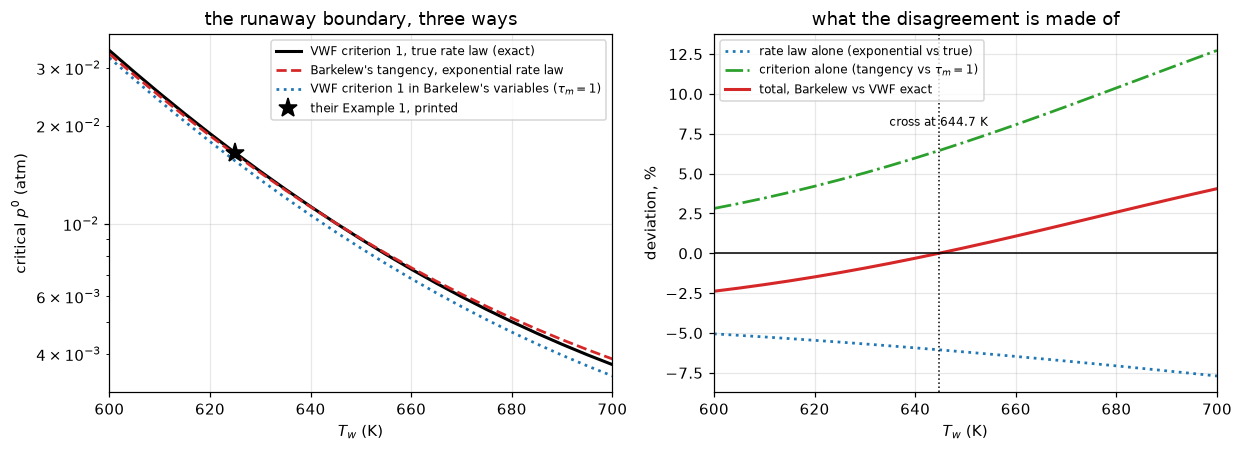

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(11.4, 4.2))
ax = axes[0]
ax.plot(CMP.Tw, CMP["p0 VWF exact (true law)"], "k-", lw=2.0,
        label="VWF criterion 1, true rate law (exact)")
ax.plot(CMP.Tw, CMP["p0 Barkelew"], "--", color="tab:red", lw=1.8,
        label="Barkelew's tangency, exponential rate law")
ax.plot(CMP.Tw, CMP["p0 crit-1 (exp law)"], ":", color="tab:blue", lw=1.8,
        label=r"VWF criterion 1 in Barkelew's variables ($\tau_m=1$)")
ax.plot([625.0], [V["p0_crit_1_at_Tw625"]], "*", color="k", ms=13,
        label="their Example 1, printed")
ax.set(xlabel="$T_w$ (K)", ylabel="critical $p^0$ (atm)", xlim=(600, 700),
       yscale="log", title="the runaway boundary, three ways")
ax.legend(fontsize=8)

ax = axes[1]
ax.plot(DEC.Tw, DEC["rate law alone %"], ":", color="tab:blue", lw=1.8,
        label="rate law alone (exponential vs true)")
ax.plot(DEC.Tw, DEC["criterion alone %"], "-.", color="tab:green", lw=1.8,
        label=r"criterion alone (tangency vs $\tau_m = 1$)")
ax.plot(DEC.Tw, DEC["total %"], "-", color="tab:red", lw=2.0,
        label="total, Barkelew vs VWF exact")
ax.axhline(0.0, color="k", lw=1.0)
ax.axvline(TW_CROSS, color="k", ls=":", lw=1.0)
ax.annotate(f"cross at {TW_CROSS:.1f} K", (TW_CROSS, 8.0), fontsize=8, ha="center")
ax.set(xlabel="$T_w$ (K)", ylabel="deviation, %", xlim=(600, 700),
       title="what the disagreement is made of")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

The two methods cross. Barkelew's chart is *more*
conservative than the true-rate criterion at low wall temperature (it allows a
lower inlet pressure) and *less* conservative at high, and the decomposition
says why. The exponential rate law on its own is conservative everywhere and by
more than the total discrepancy; the tangency criterion sits above $\tau_m = 1$
and pushes the other way by a growing amount. The two have opposite sign at
every wall temperature and the total is smaller in magnitude than either
component at all of them. That is the honest reading of *"agree extremely
well"*: the agreement is better than either approximation taken alone, and it is
better for a reason neither paper states.

### How much earlier the simplified rate law runs away

Their Fig. 3 and their Fig. 10 are the same four cases, $p^0 = 0.017$ atm and
$T_w = 625, 626, 627, 628$ K, with the true rate law and with Barkelew's. The
text says the modified equation *"leads to runaway well before the true rate
equation"*. This is what that costs. The hot spot with the true law is computed
twice: by the pymrm `Tube` on 2000 cells and refined to 16000, and by marching
the same equations as an initial-value problem.

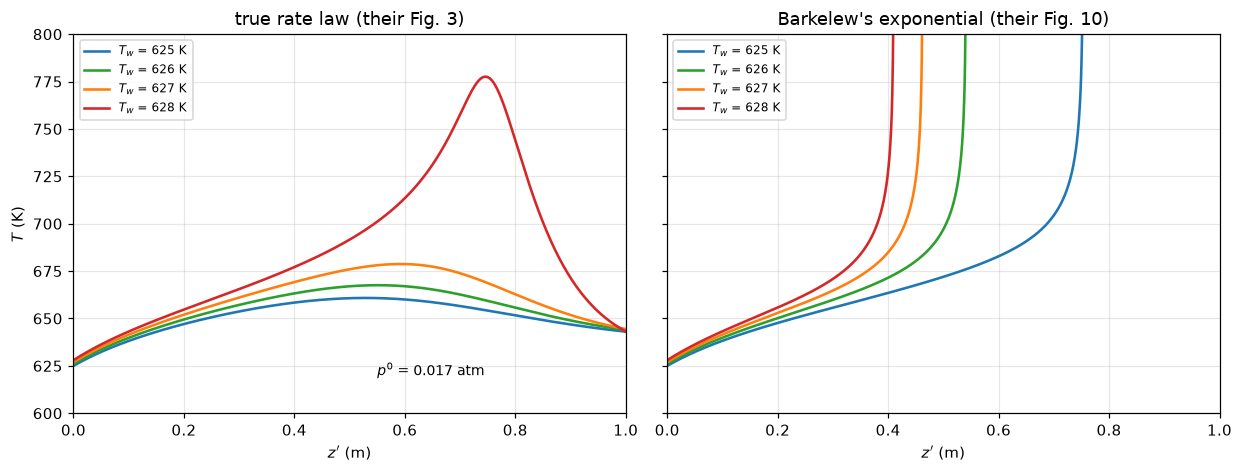

       Tw  pymrm n=2000  pymrm n=4000  pymrm n=8000  pymrm n=16000  Richardson (8000, 16000)   marched  dev n=2000 %  z' at 800 K, exponential law (m)
 625.0000      660.7792      660.8018      660.8132       660.8189                  660.8245  660.8245        0.0069                            0.7511
 626.0000      667.4837      667.5190      667.5367       667.5456                  667.5545  667.5544        0.0106                            0.5398
 627.0000      678.5868      678.6607      678.6977       678.7163                  678.7348  678.7348        0.0218                            0.4613
 628.0000      770.8533      774.1730      775.8644       776.7172                  777.5701  777.5745        0.8644                            0.4090

The pymrm tube converges at first order to the marched hot spot (observed order
0.97 at 628 K from 2000, 4000, 8000 cells), and the Richardson value
from 8000 and 16000 cells meets the march to below 0.05 K (here 4.4e-03 K).
The 0.86 % at 628 K

In [14]:
P0_FIG = V["fig10_p0"]
TW_FIG = [V[f"fig10_Tw_{i}"] for i in (1, 2, 3, 4)]
T_TOP, Z_TOP = V["fig10_T_max"], V["fig10_z_max"]


def tube_hot_spots(case=CASE, p0=P0_FIG, ns=N_TUBE_STUDY, tws=TW_FIG):
    """pymrm hot spot (K) of the true-law tube on each grid, per wall temperature."""
    return {Tw: [Tube(case, p0, Tw, n_z=n).solve().hot_spot() for n in ns] for Tw in tws}


def runaways(case=CASE, p0=P0_FIG, tws=TW_FIG):
    """March both rate laws; runaway = reaching the top of the printed axis."""
    out = []
    for Tw in tws:
        zt, Tt, zt_top = profile_ivp(case, p0, Tw, False, T_stop=T_TOP)
        zs, Ts, zs_top = profile_ivp(case, p0, Tw, True, T_stop=T_TOP)
        out.append(dict(Tw=Tw, zt=zt, Tt=Tt, zt_top=zt_top, zs=zs, Ts=Ts, zs_top=zs_top))
    return out


def runaway_counts(runs):
    """Runaways with the true and with the exponential law, and the margin of
    the classification: relative distance to 800 K (no runaway) or to the
    tube end (runaway), the smaller."""
    n_true = sum(r["zt_top"] is not None for r in runs)
    n_exp = sum(r["zs_top"] is not None for r in runs)
    m = [(T_TOP - r["Tt"].max()) / T_TOP if r["zt_top"] is None else (Z_TOP - r["zt_top"]) / Z_TOP
         for r in runs] + \
        [(T_TOP - r["Ts"].max()) / T_TOP if r["zs_top"] is None else (Z_TOP - r["zs_top"]) / Z_TOP
         for r in runs]
    return n_true, n_exp, float(min(m))


RUNS = runaways()
HS = tube_hot_spots()
N_TRUE, N_EXP, RUN_MARGIN = runaway_counts(RUNS)

fig, axes = plt.subplots(1, 2, figsize=(11.4, 4.4), sharey=True)
for r, col in zip(RUNS, ["tab:blue", "tab:green", "tab:orange", "tab:red"]):
    axes[0].plot(r["zt"], r["Tt"], color=col, lw=1.7, label=f"$T_w$ = {r['Tw']:.0f} K")
    axes[1].plot(r["zs"], r["Ts"], color=col, lw=1.7, label=f"$T_w$ = {r['Tw']:.0f} K")
for ax, ttl in zip(axes, ["true rate law (their Fig. 3)",
                          "Barkelew's exponential (their Fig. 10)"]):
    ax.set(xlabel="$z'$ (m)", xlim=(0.0, Z_TOP), ylim=(600.0, T_TOP), title=ttl)
    ax.legend(fontsize=8, loc="upper left")
axes[0].set_ylabel("$T$ (K)")
axes[0].text(0.55, 620, f"$p^0$ = {P0_FIG} atm", fontsize=9)
fig.tight_layout()
plt.show()

f3 = pd.DataFrame({"Tw": TW_FIG})
for j, n in enumerate(N_TUBE_STUDY):
    f3[f"pymrm n={n}"] = [HS[Tw][j] for Tw in TW_FIG]
f3["Richardson (8000, 16000)"] = 2 * f3["pymrm n=16000"] - f3["pymrm n=8000"]
f3["marched"] = [float(r["Tt"].max()) for r in RUNS]
f3[f"dev n={N_TUBE} %"] = ((f3[f"pymrm n={N_TUBE}"] - f3["marched"]).abs() / f3["marched"] * 100)
f3["z' at 800 K, exponential law (m)"] = [r["zs_top"] for r in RUNS]
_hs628 = np.array(HS[TW_FIG[-1]])
TUBE_ORDER = float(np.log2((_hs628[1] - _hs628[0]) / (_hs628[2] - _hs628[1])))
TUBE_DEV_WORST = float(f3[f"dev n={N_TUBE} %"].max())
TUBE_RICH_GAP = float((f3["Richardson (8000, 16000)"] - f3["marched"]).abs().max())
print(f3.to_string(index=False, float_format=lambda v: f"{v:9.4f}")
      + f"\n\nThe pymrm tube converges at first order to the marched hot spot (observed order"
      + f"\n{TUBE_ORDER:.2f} at {TW_FIG[-1]:.0f} K from 2000, 4000, 8000 cells), and the Richardson value"
      + "\nfrom 8000 and 16000 cells meets the march to below 0.05 K "
      + f"(here {TUBE_RICH_GAP:.1e} K)."
      + f"\nThe {TUBE_DEV_WORST:.2f} % at {TW_FIG[-1]:.0f} K on {N_TUBE} cells is grid error where the profile is steep."
      + f"\nWith the true rate law {N_TRUE} of the four cases reach {T_TOP:.0f} K inside the tube;"
      + f"\nwith Barkelew's exponential {N_EXP} of the same four reach the top of the paper's"
      + "\ntemperature axis before the end of the tube, which is what their Fig. 10 shows,"
      + "\nand why his chart is conservative.")

### The one printed object that can discriminate the reconstruction

Everything checked so far lives either inside the reduced system, which
contains no reference temperature at all, or compares two criteria against each
other. None of it can settle the one step of the reconstruction that the paper
does not print: the temperature at which the exponent is linearised.

Their **Fig. 10** can, because it is drawn with the simplified rate law, and the
position at which each curve leaves the top of the printed 800 K axis depends on
that choice directly. The previous cell already computed those four positions.
Comparing them is the decisive test, and it is the only one available.

> **Review status: not yet page evidence.** The four positions on the printed
> figure are *curve positions read off a scan*, not values the paper prints, so
> under this repository's rules they are a figure digitisation and need the
> maintainer's visual review before they can count. They were measured by
> `queue_cases/D2.1/review/extract_figure10.py`, which writes a numbered overlay
> for that review; they are **not** in either committed CSV and nothing else on
> this page depends on them. The case file carries a non-blocking follow-up
> asking for the review. Until it happens, read the next table as an indication.
> The reconstruction stands on the printed sentences either way; this only
> makes it decisive rather than merely consistent.

In [15]:
# ---------------------------------------------------------------------------
# QUARANTINE: the only numbers on this page taken off a curve rather than out
# of the text. Measured on a 600 dpi render of journal page 1512 by
# queue_cases/D2.1/review/extract_figure10.py, which fits each of the six marks
# (two frame edges, four curves) linearly over 72 clean rows and extrapolates to
# the top frame row where T = 800 K actually is; worst fit residual 1.5 px. The
# frame there is x = 575.5 px (z' = 0) and x = 2154.3 px (z' = 1.0 m, the
# printed axis limits), the four curves cross it at x = 1220.0, 1321.5, 1435.6
# and 1768.2 px, and the printed 0.5 tick lands 0.03 % of full scale from the
# frame midpoint. AWAITING MAINTAINER VISUAL REVIEW of the overlay that script
# writes: not in any CSV, no sidecar, and no other cell reads this dict.
FIG10_MEASURED_PENDING_REVIEW = {628.0: 0.4082, 627.0: 0.4725,
                                 626.0: 0.5448, 625.0: 0.7555}


def fig10_table(case=CASE, p0=P0_FIG, rtol=1e-10):
    """Blow-up positions and highest temperatures for every linearisation."""
    rows, hot_rows = [], []
    for Tw in TW_FIG[::-1]:                     # 628, 627, 626, 625
        row = {"Tw": Tw, "figure (pending review)": FIG10_MEASURED_PENDING_REVIEW[Tw]}
        hot = {"Tw": Tw}
        for nm, (kw, sl) in linearisations(case, Tw).items():
            z, Tmax = blowup_z(case, Tw, kw, sl, p0, length=Z_TOP, T_stop=T_TOP, rtol=rtol)
            row[nm] = z if z is not None else np.nan
            hot[nm] = Tmax
        rows.append(row)
        hot_rows.append(hot)
    fig10, hottest = pd.DataFrame(rows), pd.DataFrame(hot_rows)
    devs = pd.DataFrame({"Tw": fig10.Tw})
    for nm in linearisations(case, 625.0):
        devs[nm] = (fig10[nm] - fig10["figure (pending review)"]) \
            / fig10["figure (pending review)"] * 100
    return fig10, hottest, devs


def fig10_summary(fig10, hottest, devs):
    names = list(devs.columns[1:])
    page, alt = names[0], names[1:3]          # the wall tangent; the two permitted others
    d_page = devs[page].abs().values
    alt_d = np.concatenate([devs[nm].abs().dropna().values for nm in alt])
    n_run = {nm: int(fig10[nm].notna().sum()) for nm in names}
    # runaway margin: relative distance to 800 K (none) or to the tube end (runaway)
    marg = min(min((T_TOP - hottest[nm][fig10[nm].isna()]).min() / T_TOP
                   if fig10[nm].isna().any() else np.inf,
                   (Z_TOP - fig10[nm].dropna()).min() / Z_TOP
                   if fig10[nm].notna().any() else np.inf) for nm in names)
    return dict(page_worst=float(d_page.max()),
                n_under_1=int((d_page < 1.0).sum()),
                under_1_margin=float(np.min(np.abs(d_page - 1.0))),
                alt_min=float(alt_d.min()) if alt_d.size else np.nan,   # nan: none ran away
                alt_max=float(alt_d.max()) if alt_d.size else np.nan,
                n_run=n_run, run_margin=float(marg),
                square_z_max_mm=float(fig10[names[3]].max() * 1e3))


FIG10, HOTTEST, DEVS = fig10_table()
F10 = fig10_summary(FIG10, HOTTEST, DEVS)
LSODA_Z = [r["zs_top"] for r in RUNS][::-1]                 # 628 -> 625
RADAU_Z = list(FIG10["tangent at T_w  (this page)"])
LSODA_RADAU = max(abs(a - b) for a, b in zip(LSODA_Z, RADAU_Z))
lines = [f"z' (m) at which T reaches the printed 800 K axis, p0 = {P0_FIG} atm; "
         f"NaN = no runaway within the printed {Z_TOP:.0f} m",
         FIG10.to_string(index=False, float_format=lambda v: f"{v:8.4f}"),
         "", "deviation from the measured positions, %",
         DEVS.to_string(index=False, float_format=lambda v: f"{v:8.2f}"), ""]
for nm, n_ok in F10["n_run"].items():
    if n_ok == 0:
        lines.append(f"  {nm:30s} no runaway in any of the four cases")
    else:
        lines.append(f"  {nm:30s} {n_ok}/4 run away, |dev| {DEVS[nm].abs().min():.1f} "
                     f"to {DEVS[nm].abs().max():.1f} %")
lines += ["", "highest T reached inside the printed tube, K (800 = ran away)",
          HOTTEST.to_string(index=False, float_format=lambda v: f"{v:8.2f}"), "",
          "Not an integrator artefact: the LSODA march in z' that drew the figure above",
          "  gives " + ", ".join(f"{z:.4f}" for z in LSODA_Z) + " m",
          "  Radau in the phase plane here gives " + ", ".join(f"{z:.4f}" for z in RADAU_Z) + " m",
          f"  worst difference below 1e-6 m (here {LSODA_RADAU:.1e} m)",
          "", "With the square dropped every case ignites at the inlet: 800 K is reached by",
          f"z' = {F10['square_z_max_mm']:.2f} mm at the latest. A march in z' cannot follow that "
          "ignition (Radau",
          "stops on a step below the spacing of floating-point numbers); the phase-plane",
          "route, with the partial pressure as the independent variable, keeps both",
          "right-hand sides finite and does."]
print("\n".join(lines))

z' (m) at which T reaches the printed 800 K axis, p0 = 0.017 atm; NaN = no runaway within the printed 1 m
      Tw  figure (pending review)  tangent at T_w  (this page)  tangent at T_M  chord T_w to T_M  square dropped, a(T-T_w)/T_w
628.0000                   0.4082                       0.4090          0.5608            0.5285                        0.0002
627.0000                   0.4725                       0.4613             NaN            0.7522                        0.0003
626.0000                   0.5448                       0.5398             NaN               NaN                        0.0003
625.0000                   0.7555                       0.7511             NaN               NaN                        0.0003

deviation from the measured positions, %
      Tw  tangent at T_w  (this page)  tangent at T_M  chord T_w to T_M  square dropped, a(T-T_w)/T_w
  628.00                         0.21           37.38             29.48                        -99.94
  627.00     

The wall tangent reproduces all four printed positions,
three of them to under one percent and the fourth to 2.4 %. Every alternative
that the printed sentences permit fails *qualitatively*, not marginally.
Linearising at $T_M$, or on the chord from $T_w$ to $T_M$, weakens the
temperature dependence enough that most of the four cases never reach 800 K at
all inside the printed 1 m of tube (three of four for the $T_M$ tangent, two of
four for the chord), and the ones that do run away are off by 29 to 59 %.
Dropping the square goes the other way and makes the exponent so steep that
every case ignites at the inlet: none of the four stays below 800 K, and all of
them reach it within the first 0.3 mm of tube, against 0.4 to 0.8 m in the
figure.

So the reconstruction is not merely consistent with the printed text: subject
to the maintainer's review of those four positions, it is the only member of its
family that reproduces the paper's own figure.

## Validation

**Ranked before any code was written.** The paper offers no experiment, so the
highest available route is *a stated numerical result in the text*, and
Section 5 has exactly one, $\tau_m = 1.275$ at the tangency, plus one stated
identity, $\tau_m = 1$ for the other criterion. **No figure was digitised into
the page's data**; the only things taken from Figs. 9 and 10 into the CSVs are
the labels printed inside them, and the four Fig. 10 positions above are
quarantined and awaiting review.

| # | check | what it tests | what it cannot see |
|---|---|---|---|
| 1 | $\tau_m$ at the envelope tangency against their 1.275 | the exponential temperature dependence, and the choice of $N/S$ and $\tau_m/S$ as the collapsing groups | the dimensional definitions of $N$ and $S$ (the reduced system does not contain them) and, as measured below, all but a little of the reaction order |
| 2 | the $\tau_m = 1$ point lies right of the tangency, every $S$ | the sign and ordering claim of Section 5 | magnitude; it is a sign test |
| 3 | Barkelew's critical $p^0$ against the criterion 1 back-integration | the dimensional group definitions and the reference temperature | **nothing about $B$**: it is invariant under any rescaling of $B$ down to floating point, structurally and not by luck, hence blind to $(-\Delta H)$, $\rho_b$ and $p_B^0$, measured below. It is also nearly blind to $C$, including the $c_p\rho_g$ trap, which check 5 catches instead |
| 4 | pymrm against the phase-plane quadrature | the operator assembly, the discretisation, **and the reduced model as the finite-volume route transcribes it**: the two routes do *not* share a `reaction` function, and a defect in `BarkelewTube.reaction` alone makes the pymrm solve fail, measured below | a defect written identically into *both* transcriptions, and everything dimensional: it lives entirely inside the reduced system |
| 5 | the parameter reading against four printed derived quantities | a lost decimal point anywhere in the table, and the $c_p\rho_g$ trap | none of the model |

Checks 1 and 3 are the ones that carry weight, and they are **blind to different
things**: 1 lives entirely inside the dimensionless system and cannot see a
wrong $N$ or $S$; 3 is built on those definitions but cannot see anything that
cancels between its two routes. The tables below measure both claims rather than
asserting them.

In [16]:
# Check 4: the pymrm reactor against the phase-plane quadrature, at the four
# tangency points, plus the observed order of convergence.
def check4_table(ns=N_ZETA_STUDY, **kw):
    rows = []
    for S in S_PRINTED:
        N = TAN_U[S] * S
        ref = tau_max_phase(N, S)
        errs = [abs(tau_max_pymrm(N, S, n_z=n, **kw) - ref) / ref * 100 for n in ns]
        order = -np.polyfit(np.log(ns), np.log(errs), 1)[0] if len(ns) > 1 else np.nan
        rows.append((S, ref, *errs, order))
    return pd.DataFrame(rows, columns=["S", "tau_m reference"]
                        + [f"err {n} %" for n in ns] + ["observed order"])


CONV4 = check4_table()
CROSS_MEAN = CONV4[f"err {N_ZETA} %"].mean()
CROSS_WORST = CONV4[f"err {N_ZETA} %"].max()
ORDER4 = CONV4["observed order"].mean()
print("4. pymrm (finite volume in zeta) vs phase-plane quadrature (adaptive, no grid)\n"
      + CONV4.to_string(index=False, float_format=lambda v: f"{v:9.4f}")
      + f"\n\nmean |dev| at n_zeta = {N_ZETA}: {CROSS_MEAN:.3f} %, worst {CROSS_WORST:.3f} %; "
      + f"first-order upwind, so O(h) is\nthe expected order and {ORDER4:.2f} is what comes out.")

4. pymrm (finite volume in zeta) vs phase-plane quadrature (adaptive, no grid)
        S  tau_m reference  err 200 %  err 400 %  err 800 %  err 1600 %  observed order
   4.0000           1.2879     1.4816     0.7473     0.3749      0.1878          0.9936
   8.0000           1.2763     1.8958     0.9591     0.4820      0.2417          0.9907
  16.0000           1.2547     2.2104     1.1228     0.5660      0.2842          0.9866
  32.0000           1.2293     2.5114     1.2845     0.6507      0.3275          0.9798

mean |dev| at n_zeta = 1600: 0.260 %, worst 0.328 %; first-order upwind, so O(h) is
the expected order and 0.99 is what comes out.


### Make sure the checks can fail

Each check is now given a defect it is *presented* as guarding against, and one
it is not. A number that does not move is decoration; the point of printing this
table is to say which cells are which, and one row below is printed precisely
*because* it cannot fail. Every defect re-runs the computation behind its check;
a computation that stops (no envelope, no sign change, a reactor solve that does
not converge) is reported as such, never as a number.

In [17]:
import warnings

# The defect rows below drive the reactor into overflow on purpose; the
# warnings that produces are not results, so they are silenced for the rest
# of the page.
warnings.filterwarnings("ignore", category=RuntimeWarning)


def check1(tm=None, Ss=S_PRINTED):
    """mean |dev| of tau_m at the tangency from their 1.275 over the four
    S-curves Barkelew drew; None when the envelope ceases to exist."""
    d = []
    for S in Ss:
        _, t = tangency(S, tm)
        if t is None:
            return None
        d.append(abs(t - TAU_STATED) / TAU_STATED * 100)
    return float(np.mean(d))


def check3(T2=None, kk=None, case=CASE):
    """mean |dev| of Barkelew's critical p0 from the criterion 1 exact value."""
    return float(critical_pressures(case, T2=T2, kk=kk)["dev Barkelew vs VWF %"].abs().mean())


def check4(n_z=N_ZETA, **kw):
    """mean |dev| of the pymrm hot spot from the quadrature at the tangencies."""
    return float(check4_table(ns=(n_z,), **kw)[f"err {n_z} %"].mean())


def check5(case):
    return float(parameter_reading(case)["dev %"].max())


def attempt(fn):
    """Run a defect and say HOW it fails, not merely that it did. Returns the
    number (nan when the computation stops) and its description."""
    try:
        v = fn()
    except NewtonBreakdown:
        return np.nan, "a pymrm solve breaks down (singular Jacobian)"
    except RuntimeError:
        return np.nan, "a pymrm solve does not converge"
    except ValueError:
        return np.nan, "brentq bracketing fails (ValueError)"
    if v is None:
        return np.nan, "no sign change: the envelope is gone"
    return v, f"{v:.3f} %"


def pymrm_outcomes(**kw):
    """Per printed S: the pymrm hot spot with a defect, or why there is none."""
    out = []
    for S in S_PRINTED:
        try:
            out.append(f"S = {S:.0f}: {tau_max_pymrm(TAN_U[S] * S, S, n_z=N_ZETA, **kw):.3g}")
        except NewtonBreakdown:
            out.append(f"S = {S:.0f}: Newton breaks down")
        except RuntimeError:
            out.append(f"S = {S:.0f}: Newton does not converge")
    return "; ".join(out)


lin = lambda t: 1.0 + t                        # exp(tau) -> 1 + tau
T_M2 = lambda Tw: t_max_peak(CASE, Tw) ** 2
k_at_TM = lambda Tw: float(kexp(CASE, t_max_peak(CASE, Tw))
                           * np.exp(-CASE.a * (t_max_peak(CASE, Tw) - Tw)
                                    / t_max_peak(CASE, Tw) ** 2))
CASE_TRAP = replace(CASE, c_p=CASE.c_p * CASE.rho_g)

BASE1, BASE3, BASE4, BASE5 = MAD_CONV, DEV_MEAN, CROSS_MEAN, check5(CASE)
BASE = {1: BASE1, 3: BASE3, 4: BASE4, 5: BASE5}
C3_TM = check3(T2=T_M2, kk=k_at_TM)
DEFECTS = [
    ("exp(tau) -> 1 + tau in the reduced ODE",
     lambda: check1(lambda N, S, **kw: tau_max_phase(N, S, expo=lin)), 1),
    ("cooling term sign flipped, -N tau -> +N tau",
     lambda: check1(lambda N, S, **kw: tau_max_phase(N, S, cool=-1.0)), 1),
    ("reaction second order in y instead of first",
     lambda: check1(lambda N, S, **kw: tau_max_phase(N, S, order=2.0)), 1),
    ("linearise the rate about T_M instead of T_w", lambda: C3_TM, 3),
    ("cooling sign flipped in BarkelewTube.reaction ONLY", lambda: check4(cool=-1.0), 4),
    ("S 10 % wrong in BarkelewTube.reaction ONLY", lambda: check4(s_fac=1.1), 4),
    ("nu = 1 (cylindrical) in construct_div", lambda: check4(nu=1), 4),
    ("n_zeta = 25 cells", lambda: check4(n_z=25), 4),
    ("c_p multiplied by rho_g (the page's own headline trap)", lambda: check5(CASE_TRAP), 5),
]
OUT = {name: attempt(fn) for name, fn, _ in DEFECTS}
brk_tab = pd.DataFrame([(name, which, f"{BASE[which]:.3f} %", OUT[name][1])
                        for name, _, which in DEFECTS],
                       columns=["injected defect", "check", "before", "after"])
print("defects each check is presented as guarding against\n" + brk_tab.to_string(index=False)
      + "\n\nthe two BarkelewTube.reaction rows, per S:"
      + "\n  cooling sign flipped: " + pymrm_outcomes(cool=-1.0)
      + "\n  S 10 % high         : " + pymrm_outcomes(s_fac=1.1))

defects each check is presented as guarding against
                                       injected defect  check  before                                         after
                exp(tau) -> 1 + tau in the reduced ODE      1 1.575 %          no sign change: the envelope is gone
           cooling term sign flipped, -N tau -> +N tau      1 1.575 %          brentq bracketing fails (ValueError)
           reaction second order in y instead of first      1 1.575 %                                       1.339 %
           linearise the rate about T_M instead of T_w      3 1.767 %                                       7.210 %
    cooling sign flipped in BarkelewTube.reaction ONLY      4 0.260 % a pymrm solve breaks down (singular Jacobian)
            S 10 % wrong in BarkelewTube.reaction ONLY      4 0.260 %               a pymrm solve does not converge
                 nu = 1 (cylindrical) in construct_div      4 0.260 %                                     100.000 %
                    

In [18]:
# ---- the row that cannot fail, printed as such ------------------------------
# tau = a(T - Tw)/Tw with the square dropped enters check 3 ONLY through the
# factor T2(Tw) in p0 = Sc*A*T2(Tw)/(a*B). kk, N and the interpolated Sc are
# untouched, so p0 is multiplied by exactly 1/Tw and the deviation is
# 1 - p0/(Tw * p_ref) BY CONSTRUCTION. It is arithmetic, not evidence.
SQ_MEASURED = check3(T2=lambda Tw: Tw)
SQ_PREDICTED = float(np.mean(np.abs(CMP["p0 Barkelew"] / CMP.Tw
                                    - CMP["p0 VWF exact (true law)"])
                             / CMP["p0 VWF exact (true law)"] * 100))
SQ_GAP = abs(SQ_MEASURED - SQ_PREDICTED)
print("a row that CANNOT fail, printed so it is not mistaken for evidence\n"
      + pd.DataFrame([{
          "injected defect": "tau = a(T-T_w)/T_w, the square dropped",
          "check": 3, "before": f"{BASE3:.3f} %", "after": f"{SQ_MEASURED:.3f} %",
          "predicted from the baseline alone, no ODE re-run": f"{SQ_PREDICTED:.3f} %",
      }]).to_string(index=False)
      + f"\nthe two agree to below 1e-9 points (here {SQ_GAP:.1e}), because they are the "
      + "same arithmetic:"
      + f"\n  p0 is multiplied by exactly 1/T_w ~ 1/{CMP.Tw.mean():.0f}, so the deviation is "
      + f"forced to be about {100 * (1 - 1 / CMP.Tw.mean()):.2f} %"
      + "\n  whatever the model, the groups or the criterion happen to be. This row"
      + "\n  is a units check on one factor; it tests nothing about the reconstruction."
      + "\n  The row that DOES test the reconstruction is the T_M linearisation above,"
      + f"\n  {BASE3:.3f} % -> {C3_TM:.3f} %, and the Fig. 10 comparison earlier on the page.")

a row that CANNOT fail, printed so it is not mistaken for evidence
                       injected defect  check  before    after predicted from the baseline alone, no ODE re-run
tau = a(T-T_w)/T_w, the square dropped      3 1.767 % 99.845 %                                         99.845 %
the two agree to below 1e-9 points (here 0.0e+00), because they are the same arithmetic:
  p0 is multiplied by exactly 1/T_w ~ 1/650, so the deviation is forced to be about 99.85 %
  whatever the model, the groups or the criterion happen to be. This row
  is a units check on one factor; it tests nothing about the reconstruction.
  The row that DOES test the reconstruction is the T_M linearisation above,
  1.767 % -> 7.210 %, and the Fig. 10 comparison earlier on the page.


In [19]:
# ---- what each check is blind to, measured -----------------------------------
C3_B11 = check3(case=replace(CASE, minus_dH=CASE.minus_dH * 1.1))
C3_C12 = check3(case=replace(CASE, U=CASE.U * 1.2))
C3_TRAP = check3(case=CASE_TRAP)
C1_ORDER2 = OUT["reaction second order in y instead of first"][0]
B_MOVE = abs(C3_B11 - BASE3) / BASE3 * 100
LNK = parameter_reading(CASE)["recomputed"][1]
LNK_TRAP = parameter_reading(CASE_TRAP)["recomputed"][1]
TRAP5 = check5(CASE_TRAP)
blind = [
    ("B x 1.1, i.e. (-dH), rho_b or p_B0 10 % wrong", 3, BASE3, C3_B11,
     "check 3 sees the heat of reaction"),
    ("C x 1.2, i.e. U 20 % wrong", 3, BASE3, C3_C12,
     "check 3 sees the heat transfer coefficient"),
    ("c_p multiplied by rho_g (in B and C)", 3, BASE3, C3_TRAP, "check 3 catches the c_p trap"),
    ("reaction second order in y instead of first", 1, BASE1, C1_ORDER2,
     "the 1.275 pins the reaction order"),
]
bl = pd.DataFrame([(n, w, f"{b:.4f} %", f"{a:.4f} %",
                    "(here %.1e %%)" % (abs(a - b) / b * 100) if n.startswith("B x")
                    else f"{abs(a - b) / b * 100:.3g} %", c) for n, w, b, a, c in blind],
                  columns=["injected defect", "check", "before", "after", "relative move",
                           "claim this page does NOT make"])
print("what the checks are blind to - measured, and named as claims not made\n"
      + bl.to_string(index=False)
      + "\n\nCheck 3 does not move under a rescaling of B beyond floating point (below "
      + "1e-6 %),\nand that is structural, not luck: p0(Barkelew) is proportional to 1/B, and"
      + "\nsubstituting p = q/B removes B from their Eq. 5 and from p_M as well, so"
      + "\np0(VWF) is proportional to 1/B too. The ratio cannot move. Check 3 therefore"
      + "\nsays nothing whatever about (-dH), rho_b or p_B0."
      + "\n\nIt is also nearly blind to C, including the c_p x rho_g trap this page"
      + "\ninherits from D2.2, which lands inside anything a reader would call"
      + "\nagreement. That trap is caught by CHECK 5, not check 3: the recomputed"
      + f"\nln K goes from {LNK:.4f} to {LNK_TRAP:.4f} against the printed {V['lnK_at_Tw625']},"
      + "\nwhich is why the page says which check is not silent about it."
      + "\n\nAnd what check 1 cannot see: both group defects change only the map from"
      + "\nthe dimensional parameters to (N, S). Check 1 never reads that map (its"
      + "\nonly inputs are S and the reduced right-hand side), so those two defects"
      + f"\nleave it the IDENTICAL computation, {BASE1:.4f} %. A page quoting the"
      + "\n1.275 agreement as evidence that the groups are right would be quoting a"
      + "\nnumber that cannot see a wrong group.")

TM_NU1, TUBE_NU1 = tau_max_pymrm(TAN_U[S_PRINTED[0]] * S_PRINTED[0], S_PRINTED[0],
                                 n_z=400, nu=1, return_tube=True)
print("\nand what the nu = 1 defect actually does to the pymrm solve, which converges"
      + f"\n(Newton status {TUBE_NU1.result.status}): tau_max is at round-off "
      + f"(here {TM_NU1:.1e}), the profile is tau = 0 everywhere,"
      + "\nbecause a cylindrical divergence weights each face by its position and the"
      + "\ninlet face of this grid sits at zeta = 0: the inlet never enters. The 100 % is"
      + "\na degenerate but converged solve, not a saturated metric.")

what the checks are blind to - measured, and named as claims not made
                              injected defect  check   before    after    relative move              claim this page does NOT make
B x 1.1, i.e. (-dH), rho_b or p_B0 10 % wrong      3 1.7668 % 1.7668 % (here 1.0e-09 %)          check 3 sees the heat of reaction
                   C x 1.2, i.e. U 20 % wrong      3 1.7668 % 1.6539 %           6.39 % check 3 sees the heat transfer coefficient
         c_p multiplied by rho_g (in B and C)      3 1.7668 % 2.0120 %           13.9 %               check 3 catches the c_p trap
  reaction second order in y instead of first      1 1.5745 % 1.3386 %             15 %          the 1.275 pins the reaction order

Check 3 does not move under a rescaling of B beyond floating point (below 1e-6 %),
and that is structural, not luck: p0(Barkelew) is proportional to 1/B, and
substituting p = q/B removes B from their Eq. 5 and from p_M as well, so
p0(VWF) is proportional to 1/B too. The rat

Read the tables as follows.

**Check 1 has power over the form of the reduced system, and less of it than it
looks.** Replacing $\mathrm{e}^{\tau}$ by $1+\tau$ destroys the envelope
altogether (the $S$-curves stop having one, so there is no sign change to
bracket and no criterion), and flipping the sign of the cooling term breaks the
bracketing search one step earlier still, which is why the two failures are
reported differently: one is "no envelope", the other is a `ValueError` out of
`brentq`. But making the reaction second order in $y$ leaves check 1 *better*
than the baseline. That is not noise; it is the table saying that
$\tau_m \approx 1.275$ at the tangency is a property of the **exponential
temperature dependence**, not of the reaction order. A later cell measures how
little the order matters.

And moving the linearisation from $T_w$ to $T_M$ leaves check 1 not merely
unchanged but *the identical computation*: the reduced system contains no
reference temperature and no dimensional parameter at all.

**Check 3 sees the reference temperature**, and that is its job: the $T_M$
linearisation moves it from 1.767 % to 7.210 %. But it does not move under a
rescaling of $B$ ($B$ cancels out of both of its routes analytically) and it
barely moves under $C$. Those are not weaknesses to be glossed; they are the
reason check 5 is on the page at all, and check 5 is what catches the
$c_p\rho_g$ trap, which check 3 leaves inside anything a reader would call
agreement.

**Check 4 sees more than the discretisation.** The two routes transcribe the
reduced model independently (`tau_max_phase` writes $\mathrm{d}\tau/\mathrm{d}y$
in its own local `rhs`, `BarkelewTube.reaction` writes the $\zeta$-form
separately), so injecting a defect into the finite-volume side alone is a real
test, and it fails loudly: with the cooling sign flipped Newton breaks down on
a singular Jacobian at $S = 4$ and does not converge at the other three, and
with $S$ 10 % high it does not converge at the two larger $S$ and lands far from
the reference at the two smaller ones. What it
cannot see is a defect written the same way into both, and anything
dimensional. The `nu = 1` row is a degenerate solve rather than an inaccurate
one: a cylindrical divergence weights each face by its position and the inlet
face of this grid is at $\zeta = 0$, so the inlet never enters and the whole
profile is zero. The last cell prints that value so the result is not mistaken
for a saturated metric.

**One row is printed because it cannot fail.** Dropping the square multiplies
$p^0$ by exactly $1/T_w$ and nothing else, so its 99.8 % is forced by
arithmetic, as the cell demonstrates by reproducing it from the baseline
numbers without re-running a single ODE. It is a scale check on one factor and
it is evidence for nothing.

None of the checks is redundant, and none of them is sufficient. That is why all
of them are printed.

In [20]:
# How much of the 1.275 belongs to the exponential and how much to the
# first-order kinetics? Re-derive the tangency for three reaction orders.
def order_study(orders=(0.5, 1.0, 2.0), expo=np.exp):
    ts, us = [], []
    for n in orders:
        tm_n = lambda N, S, n=n, **kw: tau_max_phase(N, S, order=n, expo=expo)
        tg = [tangency(S, tm_n) for S in S_PRINTED]
        ts.append([n] + [t for _, t in tg])
        us.append([n] + [u for u, _ in tg])
    tv, uv = np.array(ts)[:, 1:], np.array(us)[:, 1:]
    return ts, us, dict(tmin=tv.min(), tmax=tv.max(),
                        spread=100 * (tv.max() - tv.min()) / tv.min(),
                        u_lo=uv[-1, 0], u_hi=uv[0, 0], factor=uv[0, 0] / uv[-1, 0])


ORD_T, ORD_U, ORD = order_study()
cols = ["reaction order"] + [f"S={S:.0f}" for S in S_PRINTED]
print("tau_m at the tangency (the ordinate of Barkelew's critical point)\n"
      + pd.DataFrame(ORD_T, columns=cols).to_string(index=False, float_format=lambda v: f"{v:7.4f}")
      + "\n\nN/S at the tangency (its abscissa)\n"
      + pd.DataFrame(ORD_U, columns=cols).to_string(index=False, float_format=lambda v: f"{v:7.4f}")
      + "\n\nOver reaction orders 0.5 to 2 and S = 4 to 32 the tangency hot spot stays"
      + f"\ninside {ORD['tmin']:.3f} to {ORD['tmax']:.3f}, a spread of {ORD['spread']:.1f} %, no wider "
      + "than the spread with"
      + f"\nS alone. The abscissa is a different matter: at S = 4 it moves from "
      + f"{ORD['u_lo']:.3f} to {ORD['u_hi']:.3f},"
      + f"\na factor of {ORD['factor']:.2f}. So their 1.275 characterises the exponential"
      + "\ntemperature dependence and says almost nothing about the reaction order,"
      + "\nwhile the chart itself is order-specific. Check 1 should be read that way"
      + "\nand no further.")

tau_m at the tangency (the ordinate of Barkelew's critical point)
 reaction order     S=4     S=8    S=16    S=32
         0.5000  1.3149  1.2771  1.2424  1.2108
         1.0000  1.2879  1.2763  1.2547  1.2293
         2.0000  1.2550  1.2689  1.2624  1.2454

N/S at the tangency (its abscissa)
 reaction order     S=4     S=8    S=16    S=32
         0.5000  1.2887  1.7807  2.1053  2.3188
         1.0000  0.9440  1.4625  1.8563  2.1380
         2.0000  0.5749  1.0785  1.5307  1.8887

Over reaction orders 0.5 to 2 and S = 4 to 32 the tangency hot spot stays
inside 1.211 to 1.315, a spread of 8.6 %, no wider than the spread with
S alone. The abscissa is a different matter: at S = 4 it moves from 0.575 to 1.289,
a factor of 2.24. So their 1.275 characterises the exponential
temperature dependence and says almost nothing about the reaction order,
while the chart itself is order-specific. Check 1 should be read that way
and no further.


### Claims

Every number the page states is registered below with how it is checked
(`docs/claims-design.md`): a **value** held to a tolerance against the committed
baseline, a **bound** with its basis, or an **exact** result with its margin to
the threshold that decided it. The prose numbers are checked against them with
`claims.says`.

In [21]:
# Discretisation and quadrature results: values held tightly, because the
# quadrature (rtol 1e-9) and the extrapolated tangency are reproducible far
# below these tolerances and a break row must be able to fail them.
for S in S_PRINTED + [200.0]:
    claims.value(f"tau_m_tangency_S{S:.0f}", TAN_T[S] if S in TAN_T else CONV[S], rtol=1e-5)
claims.value("tau_m_tangency_mad_pct_drawn", MAD_DRAWN, rtol=1e-4, unit="%")
claims.value("tau_m_tangency_mad_pct_wide", MAD_WIDE, rtol=1e-4, unit="%")
claims.exact("tau_m_tangency_peak_S", PEAK_S, margin=PEAK_MARGIN, min_margin=1e-5,
             note="argmax over S_WIDE; margin: relative lead over the next largest")
claims.value("tau_m_drop_S4_S32", DROP_4_32, rtol=1e-4)
claims.value("gap_right_S4_pct", GAPS[S_WIDE.index(4.0)], rtol=1e-4, unit="%")
claims.value("gap_right_S200_pct", GAPS[-1], rtol=1e-4, unit="%")
claims.count("gap_right_positive_count", GAPS, 0.0, min_margin=0.1, relative=False,
             note="criterion 1 right of the tangency; margin in % of N/S")
# The finest step's error is only some tens of times the tolerance noise (the
# Richardson pair gap), not the 1e3 of claims-design: the order is indicative,
# so its range is a chosen bound, and the ratio is published beside it.
TAN_FINEST_ERR = min(abs(RAW[S][0.0025] - CONV[S]) / CONV[S] for S in RAW)
TAN_ERR_OVER_NOISE = TAN_FINEST_ERR / (RICH_GAP / 100)
claims.bound("tangency_truncation_order", ORDER_H, min=1.9, max=2.1, basis="chosen",
             note="centred difference in ln S, O(h^2); indicative, finest-h error only "
                  "tens of times the tolerance noise")
claims.bound("tangency_finest_error_over_noise", TAN_ERR_OVER_NOISE, min=5.0, basis="chosen",
             note="finest-h error over the Richardson pair gap; below the 1e3 a "
                  "convergence order needs, so the order above is indicative")
claims.bound("richardson_pair_gap_pct", RICH_GAP, max=1e-4, basis="tolerance", unit="%",
             note="brentq xtol 1e-8 on N/S, quadrature rtol 1e-9")
claims.value("bias_h004_S4_pct", abs(BIAS_S4), rtol=1e-4, unit="%")
claims.value("bias_h004_S200_pct", abs(BIAS_S200), rtol=1e-4, unit="%")
claims.value("drift_h004_pct", DRIFT_H004, rtol=1e-4, unit="%")
claims.value("drift_converged_pct", DRIFT_CONV, rtol=1e-4, unit="%")
claims.value("drift_inflation_points", INFLATION, rtol=1e-4, unit="%")
claims.value("drift_inflation_pct", INFLATION / abs(DRIFT_CONV) * 100, rtol=1e-4, unit="%")
claims.bound("tau_drawn_max", TAU_DRAWN_MAX, max=13.0, basis="chosen",
             note="Fig. 9 ordinate 0.4 times S = 32; the quadrature cap 20 must not bind")

# the real tube
claims.value("barkelew_vs_vwf_mean_dev_pct", DEV_MEAN, rtol=1e-4, unit="%")
claims.value("barkelew_vs_vwf_worst_dev_pct", DEV_WORST, rtol=1e-4, unit="%")
claims.value("rate_law_alone_dev_pct_600K", DEC["rate law alone %"].iloc[0], rtol=1e-4, unit="%")
claims.value("rate_law_alone_dev_pct_700K", DEC["rate law alone %"].iloc[-1], rtol=1e-4, unit="%")
claims.value("criterion_alone_dev_pct_600K", DEC["criterion alone %"].iloc[0], rtol=1e-4, unit="%")
claims.value("criterion_alone_dev_pct_700K", DEC["criterion alone %"].iloc[-1], rtol=1e-4,
             unit="%")
claims.value("p0_crit_vwf_at_625K", P0_VWF_625, rtol=1e-6, unit="atm")
claims.value("p0_crit_barkelew_at_625K", P0_BK_625, rtol=1e-5, unit="atm")
claims.bound("p0_crit_vwf_vs_printed_pct", VWF_VS_PRINTED, max=0.0303, basis="theory", unit="%",
             note="half a unit in the last printed place of 0.01651 atm")
claims.value("tw_cross_K", TW_CROSS, rtol=1e-5, unit="K")
claims.count("decomposition_opposite_sign_count", OPP, 0.0, min_margin=0.5, relative=False,
             note="margin: smallest component, % points")
claims.count("decomposition_total_smaller_count", LEAD, 0.0, min_margin=0.1, relative=False,
             note="margin: smallest lead of the smaller component over the total, % points")
claims.bound("decomposition_product_gap", PRODUCT_GAP, max=1e-10, basis="identity",
             structural=True, unit="%", note="the two factors multiply to the total by algebra")

# the dimensional tube, their Figs. 3 and 10
claims.value("tube_dev_n2000_worst_pct", TUBE_DEV_WORST, rtol=1e-3, unit="%")
claims.bound("tube_grid_order_628K", TUBE_ORDER, min=0.9, max=1.1, basis="theory",
             note="first-order upwind, 2000-4000-8000 cells")
TUBE_ERR_OVER_NOISE = abs(_hs628[2] - f3["marched"].iloc[-1]) / (1e-10 * TW_FIG[-1])
claims.bound("tube_finest_error_over_noise", TUBE_ERR_OVER_NOISE, min=1e3, basis="tolerance",
             note="error at 8000 cells over newton tol 1e-10 times T_w (march rtol 1e-10)")
claims.bound("tube_richardson_vs_march_K", TUBE_RICH_GAP, max=0.05, basis="chosen", unit="K",
             note="O(h^2) remainder of first-order Richardson at 8000/16000 cells")
claims.exact("runaways_true_law", N_TRUE, margin=RUN_MARGIN, min_margin=0.01,
             note="margin: relative distance to 800 K or to the tube end")
claims.exact("runaways_exponential_law", N_EXP, margin=RUN_MARGIN, min_margin=0.01)
claims.value("fig10_page_worst_dev_pct", F10["page_worst"], rtol=1e-3, unit="%",
             note="against positions pending maintainer review")
claims.exact("fig10_page_n_under_1pct", F10["n_under_1"], margin=F10["under_1_margin"],
             min_margin=0.01, note="margin in % points from 1 %")
claims.value("fig10_alt_dev_min_pct", F10["alt_min"], rtol=1e-3, unit="%")
claims.value("fig10_alt_dev_max_pct", F10["alt_max"], rtol=1e-3, unit="%")
for key, nm in (("TM_tangent", "tangent at T_M"), ("chord", "chord T_w to T_M"),
                ("square", "square dropped, a(T-T_w)/T_w")):
    claims.exact(f"fig10_{key}_no_runaway", 4 - F10["n_run"][nm], margin=F10["run_margin"],
                 min_margin=0.01, note="margin: relative distance to 800 K or to the tube end")
claims.value("fig10_square_z_max_mm", F10["square_z_max_mm"], rtol=1e-3, unit="mm")
claims.bound("lsoda_vs_radau_m", LSODA_RADAU, max=1e-6, basis="tolerance", unit="m",
             note="both integrators at rtol 1e-10")

# validation
claims.value("cross_method_mean_pct", CROSS_MEAN, rtol=1e-3, unit="%")
claims.value("cross_method_worst_pct", CROSS_WORST, rtol=1e-3, unit="%")
claims.bound("cross_method_grid_order", ORDER4, min=0.95, max=1.05, basis="theory",
             note="first-order upwind, 200 to 1600 cells")
CROSS_ERR_OVER_NOISE = CONV4[f"err {N_ZETA} %"].min() / 100 / 1e-9
claims.bound("cross_method_finest_error_over_noise", CROSS_ERR_OVER_NOISE, min=1e3,
             basis="tolerance", note="error at 1600 cells over quadrature rtol 1e-9 "
                                     "(newton tol 1e-10 is smaller)")
claims.bound("interp_vs_root_p0_rel", INTERP_GAP, max=2e-3, basis="chosen",
             note="plotting statement: the envelope and the first brackets come from the "
                  "PCHIP through the 13 tangencies; published values are roots")
claims.value("zeta_peak_S4", ZETA_PEAK[S_PRINTED[0]], rtol=1e-3)
claims.value("zeta_peak_S32", ZETA_PEAK[S_PRINTED[-1]], rtol=1e-3)
claims.value("check5_worst_pct", BASE5, rtol=1e-3, unit="%")
claims.value("check5_cp_trap_pct", TRAP5, rtol=1e-3, unit="%")
claims.value("check3_TM_pct", C3_TM, rtol=1e-4, unit="%")
claims.value("check3_cp_trap_pct", C3_TRAP, rtol=1e-4, unit="%")
claims.bound("check3_B_rescale_move_pct", B_MOVE, max=1e-6, basis="identity", structural=True,
             unit="%", note="B cancels between the two routes: p0 proportional to 1/B in both")
claims.bound("square_dropped_pct", SQ_MEASURED, min=99.8, max=99.9, basis="identity",
             structural=True, unit="%", note="1 - 1/T_w by arithmetic; the row that cannot fail")
claims.bound("square_dropped_gap", SQ_GAP, max=1e-9, basis="identity", structural=True,
             unit="%", note="measured and predicted are the same arithmetic")
claims.value("order_tau_min", ORD["tmin"], rtol=1e-4)
claims.value("order_tau_max", ORD["tmax"], rtol=1e-4)
claims.value("order_spread_pct", ORD["spread"], rtol=1e-4, unit="%")
claims.value("order_abscissa_factor_S4", ORD["factor"], rtol=1e-4)

# prose
claims.says("0.5", "zeta_peak_S4")                      # PyMRM implementation
claims.says("0.1", "zeta_peak_S32")
claims.says("below 13", "tau_drawn_max")
claims.says("0.09", "bias_h004_S4_pct")                 # Results, step size
claims.says("0.66", "bias_h004_S200_pct")
claims.says("0.5", "drift_inflation_points")
claims.says("5", "drift_inflation_pct")
claims.says("4", "tau_m_tangency_peak_S")               # Does it collapse?
claims.says("0.06", "tau_m_drop_S4_S32")
claims.says("24", "gap_right_S4_pct")
claims.says("1.2", "gap_right_S200_pct")
claims.says("3", "fig10_page_n_under_1pct")             # Fig. 10
claims.says("2.4", "fig10_page_worst_dev_pct")
claims.says("3", "fig10_TM_tangent_no_runaway")
claims.says("2", "fig10_chord_no_runaway")
claims.says("29", "fig10_alt_dev_min_pct")
claims.says("59", "fig10_alt_dev_max_pct")
claims.says("0.3", "fig10_square_z_max_mm")
claims.says("1.767", "barkelew_vs_vwf_mean_dev_pct")    # Read the tables
claims.says("7.210", "check3_TM_pct")
claims.says("99.8", "square_dropped_pct")
print(f"{len(claims.metrics)} claims registered, {sum(len(v) for v in claims.quoted.values())} "
      "prose literals checked")

68 claims registered, 21 prose literals checked


### The defect-injection table

Each row breaks one thing on purpose, **re-runs** the computation behind one or
more claims with the defect in place, and hands the result to `claims.breaks`,
which records whether the claim's own check (its tolerance, bound or margin)
catches it. A computation that stops under the defect is recorded as `nan`,
which every check catches. Every claim that is not structural must be failed by
at least one row, and the last cell of the page raises otherwise.

In [22]:
BREAK = []


def brk(name, metric, value, note=""):
    """One injected defect: ``value`` is what claim ``metric`` becomes with it."""
    caught = claims.breaks(name, metric, value)
    clean = claims[metric]
    if claims.metrics[metric]["kind"] == "bound":
        clean = f"(here {clean:.3g})"      # a bound's own value is not published: masked
    BREAK.append(dict(defect=name, metric=metric, clean=clean, broken=value,
                      caught=caught, note=note))


# --- the step size: a fixed h = 0.04, not extrapolated --------------------------
H004 = "fixed step h = 0.04 in ln S, not extrapolated"
for S in S_PRINTED + [200.0]:
    brk(H004, f"tau_m_tangency_S{S:.0f}", RAW[S][0.04])
brk(H004, "tau_m_tangency_mad_pct_drawn", MAD_H004)
brk(H004, "tau_m_drop_S4_S32", RAW[4.0][0.04] - RAW[32.0][0.04])


def tangency_one_sided(S, h):
    """Defect: the crossing of the curves S and S e^h (a one-sided difference)."""
    Sp = S * np.exp(h)
    f = lambda u: tau_max_phase(u * Sp, Sp) / Sp - tau_max_phase(u * S, S) / S
    ur = brentq(f, u_at_tau(S, 1.7), u_at_tau(S, 0.7), xtol=1e-8)
    return tau_max_phase(ur * S, S)


brk("one-sided difference (S, S e^h) instead of centred", "tangency_truncation_order",
    truncation_order({S: {h: tangency_one_sided(S, h) for h in H_STUDY} for S in (4.0, 200.0)},
                     {S: CONV[S] for S in (4.0, 200.0)}))
brk("second Richardson pair (0.02, 0.01) instead of (0.005, 0.0025)", "richardson_pair_gap_pct",
    max(abs((4 * RAW[S][0.01] - RAW[S][0.02]) / 3 - RICH1[S]) / CONV[S] * 100 for S in RAW))
brk("the stated 1.275 read as 1.257", "tau_m_tangency_mad_pct_wide",
    float(np.mean([abs(TAN_T[S] - 1.257) / 1.257 * 100 for S in S_WIDE])))

# --- second-order kinetics, re-derived where each claim needs it ------------------
ORD2 = "reaction second order in y instead of first"
tm2 = lambda N, S, **kw: tau_max_phase(N, S, order=2.0)
RAW2, _, CONV2 = step_study(Ss=[4.0, 200.0], hs=(0.04, 0.01, 0.005, 0.0025), tm=tm2)
brk(ORD2, "bias_h004_S4_pct", abs(RAW2[4.0][0.04] - CONV2[4.0]) / CONV2[4.0] * 100)
brk(ORD2, "bias_h004_S200_pct", abs(RAW2[200.0][0.04] - CONV2[200.0]) / CONV2[200.0] * 100)
_d04, _dc = drift({S: RAW2[S][0.04] for S in RAW2}), drift(CONV2)
brk(ORD2, "drift_h004_pct", _d04)
brk(ORD2, "drift_converged_pct", _dc)
brk(ORD2, "drift_inflation_points", abs(_d04 - _dc))
brk(ORD2, "drift_inflation_pct", abs(_d04 - _dc) / abs(_dc) * 100)
_t2 = {S: tangency(S, tm2) for S in (3.0, 4.0, 6.0, 8.0, 200.0)}
brk(ORD2 + " (peak searched over S = 3 to 8)", "tau_m_tangency_peak_S",
    float(max((3.0, 4.0, 6.0, 8.0), key=lambda S: _t2[S][1])))
for S, metric in ((4.0, "gap_right_S4_pct"), (200.0, "gap_right_S200_pct")):
    brk(ORD2, metric, (u_at_tau(S, 1.0, tm2) - _t2[S][0]) / _t2[S][0] * 100)

# --- criterion 1 placed at tau_m = 1.3 -------------------------------------------
C13 = "criterion 1 placed at tau_m = 1.3 instead of 1"
ONE_U13 = {S: u_at_tau(S, 1.3) for S in S_WIDE}
brk(C13, "gap_right_positive_count",
    int(sum(ONE_U13[S] > TAN_U[S] for S in S_WIDE)))
_opp13, _lead13 = decomposition_margins(decompose(critical_pressures(level=1.3)))
brk(C13, "decomposition_opposite_sign_count", int((_opp13 > 0).sum()))
brk(C13, "decomposition_total_smaller_count", int((_lead13 > 0).sum()))

# --- the units trap: c_p multiplied by rho_g, in B and C --------------------------
TRAP = "c_p multiplied by rho_g (the units trap)"
CMP_T = critical_pressures(CASE_TRAP)
DEC_T = decompose(CMP_T)
brk(TRAP, "barkelew_vs_vwf_mean_dev_pct", CMP_T["dev Barkelew vs VWF %"].abs().mean())
brk(TRAP, "barkelew_vs_vwf_worst_dev_pct", CMP_T["dev Barkelew vs VWF %"].abs().max())
brk(TRAP, "rate_law_alone_dev_pct_600K", DEC_T["rate law alone %"].iloc[0])
brk(TRAP, "rate_law_alone_dev_pct_700K", DEC_T["rate law alone %"].iloc[-1])
brk(TRAP, "criterion_alone_dev_pct_600K", DEC_T["criterion alone %"].iloc[0])
brk(TRAP, "criterion_alone_dev_pct_700K", DEC_T["criterion alone %"].iloc[-1])
brk(TRAP, "p0_crit_vwf_at_625K", CMP_T["p0 VWF exact (true law)"][I625])
brk(TRAP, "p0_crit_barkelew_at_625K", CMP_T["p0 Barkelew"][I625])
brk(TRAP, "p0_crit_vwf_vs_printed_pct",
    abs(CMP_T["p0 VWF exact (true law)"][I625] - V["p0_crit_1_at_Tw625"])
    / V["p0_crit_1_at_Tw625"] * 100)
brk(TRAP, "tw_cross_K", crossing(CASE_TRAP)[0])
brk(TRAP, "check5_worst_pct", TRAP5)
brk(TRAP, "check3_TM_pct", check3(T2=T_M2, kk=k_at_TM, case=CASE_TRAP))
F10_T = fig10_summary(*fig10_table(CASE_TRAP))
for metric, key in (("fig10_page_worst_dev_pct", "page_worst"),
                    ("fig10_alt_dev_min_pct", "alt_min"), ("fig10_alt_dev_max_pct", "alt_max"),
                    ("fig10_square_z_max_mm", "square_z_max_mm")):
    brk(TRAP, metric, F10_T[key])
brk("trap applied to C only (B left as printed)", "check5_cp_trap_pct",
    check5(replace(CASE, c_p=CASE.c_p * CASE.rho_g, minus_dH=CASE.minus_dH * CASE.rho_g)))
brk("trap applied to B only (C left as printed)", "check3_cp_trap_pct",
    check3(case=replace(CASE, c_p=CASE.c_p * CASE.rho_g, U=CASE.U * CASE.rho_g)))

# --- the critical S read off the table instead of solved for ---------------------
brk("critical S read off the interpolant through the 13 tangencies",
    "p0_crit_barkelew_at_625K", CMP_INTERP["p0 Barkelew"][I625])
_s_of_n_coarse = PchipInterpolator(np.log([TAN_U[S] * S for S in S_WIDE[::2]]),
                                   np.log(S_WIDE[::2]))
_p0_coarse = [float(np.exp(_s_of_n_coarse(np.log(N)))) * CASE.A * Tw ** 2 / (CASE.a * CASE.B)
              for Tw, N in zip(CMP.Tw, CMP.N)]
brk("interpolant through every other tangency", "interp_vs_root_p0_rel",
    float(np.max(np.abs(np.array(_p0_coarse) - CMP["p0 Barkelew"]) / CMP["p0 Barkelew"])))

# --- the linearisation of the rate law ------------------------------------------
TML = "linearise the rate about T_M instead of T_w"
_dec_tm = decompose(critical_pressures(T2=T_M2, kk=k_at_TM))
brk(TML, "barkelew_vs_vwf_mean_dev_pct", C3_TM)
brk(TML, "decomposition_total_smaller_count",
    int((decomposition_margins(_dec_tm)[1] > 0).sum()))

# --- the inlet pressure of their Figs. 3 and 10 -----------------------------------
P020 = "inlet pressure 0.020 atm instead of 0.017"
_n_true, _n_exp, _ = runaway_counts(runaways(p0=0.020))
brk(P020, "runaways_true_law", _n_true)
F10_P = fig10_summary(*fig10_table(p0=0.020))
for key, nm in (("TM_tangent", "tangent at T_M"), ("chord", "chord T_w to T_M")):
    brk(P020, f"fig10_{key}_no_runaway", 4 - F10_P["n_run"][nm])
brk(P020, "fig10_page_n_under_1pct", F10_P["n_under_1"])


def _square_no_runaway_status_ignored():
    """The square-dropped cases marched in z', a stopped integration read as
    'no runaway': the defect is the reading, not the model."""
    n = 0
    for Tw in TW_FIG:
        try:
            z, _ = blowup_z(CASE, Tw, *linearisations(CASE, Tw)["square dropped, a(T-T_w)/T_w"],
                            P0_FIG, length=Z_TOP, T_stop=T_TOP, route="z")
        except RuntimeError:
            z = None
        n += z is None
    return n


brk("a stopped march in z' read as no runaway", "fig10_square_no_runaway",
    _square_no_runaway_status_ignored())
P012 = "inlet pressure 0.012 atm instead of 0.017"
brk(P012, "runaways_exponential_law", runaway_counts(runaways(p0=0.012))[1])

# --- discretisation and integrators ------------------------------------------------
_hs1000 = [Tube(CASE, P0_FIG, Tw, n_z=1000).solve().hot_spot() for Tw in TW_FIG]
brk("tube on 1000 cells", "tube_dev_n2000_worst_pct",
    max(abs(h - m) / m * 100 for h, m in zip(_hs1000, f3["marched"])))
_hs6000 = Tube(CASE, P0_FIG, TW_FIG[-1], n_z=6000).solve().hot_spot()
brk("third grid 6000 cells, read as a doubling", "tube_grid_order_628K",
    float(np.log2((_hs628[1] - _hs628[0]) / (_hs6000 - _hs628[1]))))
brk("Richardson with the second-order factor 4/3", "tube_richardson_vs_march_K",
    float(((4 * f3["pymrm n=16000"] - f3["pymrm n=8000"]) / 3 - f3["marched"]).abs().max()))
brk("Radau at rtol 1e-4", "lsoda_vs_radau_m",
    max(abs(a - blowup_z(CASE, Tw, *linearisations(CASE, Tw)["tangent at T_w  (this page)"],
                         P0_FIG, length=Z_TOP, T_stop=T_TOP, rtol=1e-4)[0])
        for a, Tw in zip(LSODA_Z, TW_FIG[::-1])))
brk("n_zeta = 25 cells", "cross_method_mean_pct", OUT["n_zeta = 25 cells"][0])
brk("nu = 1 (cylindrical) in construct_div", "cross_method_mean_pct",
    OUT["nu = 1 (cylindrical) in construct_div"][0])
brk("cooling sign flipped in BarkelewTube.reaction only", "cross_method_mean_pct",
    OUT["cooling sign flipped in BarkelewTube.reaction ONLY"][0], "solve fails: nan")
brk("S 10 % high in BarkelewTube.reaction only", "cross_method_mean_pct",
    OUT["S 10 % wrong in BarkelewTube.reaction ONLY"][0], "solve fails: nan")
brk("reactor on n_zeta = 800", "cross_method_worst_pct", CONV4["err 800 %"].max())
_ref3 = {S: tau_max_phase(TAN_U[S] * S, S, rtol=1e-3) for S in S_PRINTED}
brk("reference quadrature at rtol 1e-3", "cross_method_finest_error_over_noise",
    min(abs(tau_max_pymrm(TAN_U[S] * S, S, n_z=N_ZETA) - _ref3[S]) / _ref3[S]
        for S in S_PRINTED) / 1e-3)
brk("second Richardson pair (0.02, 0.01) as the noise", "tangency_finest_error_over_noise",
    TAN_FINEST_ERR / max(abs((4 * RAW[S][0.01] - RAW[S][0.02]) / 3 - RICH1[S]) / CONV[S]
                         for S in RAW))
_t8000_loose = Tube(CASE, P0_FIG, TW_FIG[-1], n_z=8000).solve(tol=1e-3).hot_spot()
brk("tube newton tol 1e-3", "tube_finest_error_over_noise",
    abs(_t8000_loose - f3["marched"].iloc[-1]) / (1e-3 * TW_FIG[-1]))
_e2400 = check4_table(ns=(2400,))["err 2400 %"].values
brk("last grid 2400 cells, read as a doubling", "cross_method_grid_order",
    float(np.mean([-np.polyfit(np.log(N_ZETA_STUDY),
                               np.log([*CONV4.iloc[i, 2:5], _e2400[i]]), 1)[0]
                   for i in range(len(S_PRINTED))])))
for S, metric in ((S_PRINTED[0], "zeta_peak_S4"), (S_PRINTED[-1], "zeta_peak_S32")):
    _, _tube = tau_max_pymrm(TAN_U[S] * S, S, n_z=25, return_tube=True)
    brk("n_zeta = 25 cells", metric, float(_tube.z_c[np.argmax(_tube.u[:, 1])]))
brk("Fig. 9 ordinate limit read as 0.5", "tau_drawn_max",
    max(float((vv * S).max()) for S, (uu, vv) in s_curves(0.5, Ss=[32.0]).items()))

# --- the exponent: lambda tau with lambda = 1.1 -------------------------------------
LAM = "exponent 1.1 tau instead of tau"
_, _, ORD_L = order_study(expo=lambda t: np.exp(1.1 * t))
for metric, key in (("order_tau_min", "tmin"), ("order_tau_max", "tmax"),
                    ("order_spread_pct", "spread"), ("order_abscissa_factor_S4", "factor")):
    brk(LAM, metric, ORD_L[key])

print(pd.DataFrame(BREAK).to_string(index=False, formatters={
    "clean": lambda v: f"{v:.5g}" if isinstance(v, float) else str(v),
    "broken": lambda v: f"{v:.5g}" if isinstance(v, float) else str(v)}))

                                                                     defect                               metric           clean     broken  caught             note
                              fixed step h = 0.04 in ln S, not extrapolated                    tau_m_tangency_S4          1.2879     1.2868    True                 
                              fixed step h = 0.04 in ln S, not extrapolated                    tau_m_tangency_S8          1.2763     1.2746    True                 
                              fixed step h = 0.04 in ln S, not extrapolated                   tau_m_tangency_S16          1.2547     1.2521    True                 
                              fixed step h = 0.04 in ln S, not extrapolated                   tau_m_tangency_S32          1.2293     1.2257    True                 
                              fixed step h = 0.04 in ln S, not extrapolated                  tau_m_tangency_S200          1.1622     1.1545    True                 
          

## What pymrm adds

**The envelope is computed rather than drawn.** Barkelew's construction is a
tangency between a curve and the envelope of a family, and in 1959 both had to
be drawn and the tangency judged by eye, which is why Section 5 can only report
that $\tau_m$ there was *"very close to"* one number, and why the crosses on
their Fig. 9 sit where a draughtsman put them. Solving the reduced system on
demand makes the envelope the *locus of tangency points* (one bracketed root
per $S$, at a step size extrapolated until the answer no longer depends on it),
so the tangency $\tau_m$ becomes a quantity with a value at every $S$ rather
than a constant asserted for four of them. That is what makes the drift visible
at all, and the step-size study is what makes the drift trustworthy: the naive
fixed step biases it in exactly the direction that would have flattered the
conclusion.

**The two criteria can be put in one picture in dimensional variables, and then
taken apart.** Section 5's comparison is qualitative in the text and graphical
in Fig. 8, and mixes rate laws: Barkelew's values use his exponential, theirs
use the true Arrhenius factor. Computing the intermediate case (their criterion,
his rate law) factorises the difference exactly into a rate-law part and a
criterion part, and the answer is that they have opposite signs at every wall
temperature and partly cancel. Neither paper states that, and it is why "agree
extremely well" is true.

**And the range is no longer set by what fits on a sheet of paper.** Barkelew
drew four curves, $S = 4$ to 32; the collapse is tested here from $S = 3$ to
200 at no extra cost, which is where a similarity reduction is supposed to be
interrogated.

**The pymrm reactor is the cross-check, not the workhorse.** The diagram is
drawn by quadrature, which is cheaper and more accurate for a two-equation
initial-value problem; the finite-volume `BarkelewTube` confirms it at the four
tangency points to the first-order upwind error, and the dimensional `Tube`
converges under refinement onto the marched hot spots of their Fig. 3.

**What this page does not add.** It does not improve on either method. Both are
cheap; the reactor here is a two-equation ODE and the full sweep takes seconds.
Nothing here is validated against a measurement, and neither source paper
contains one.

## Reuse

The dimensionless system is the *generic* first-order exothermic tube, so the
diagram is reusable as it stands: compute $N = C/(A k_w)$ and
$S = a(\Delta T)_{ad}/T_w^2$ for the tube in hand (`n_group`, `s_group` in
`model.py`) and read the critical $S$ off the tangency locus. Nothing in
`BarkelewTube` or `tau_max_phase` is specific to this chemistry.

Three ways to extend it:

- **A different reaction order.** In the quadrature route this is the `order`
  argument of `tau_max_phase`, which the validation section already uses for
  $n = \tfrac12, 1, 2$: the tangency $\tau_m$ barely moves, so the chart is far
  more general than "first order" suggests, though the *position* of the
  tangency in $N/S$ does shift. To cross-check it with pymrm, change
  `BarkelewTube.reaction` to $y^n \mathrm{e}^{\tau}$ in the same way; the rest of
  the machinery is untouched.
- **Keep the true Arrhenius factor.** Replace $\mathrm{e}^{\tau}$ by
  $\exp[\tau/(1+\tau/\gamma)]$ with $\gamma = a/T_w$ in both routes and the
  family gains a third parameter. The collapse then holds only asymptotically
  as $\gamma \to \infty$, and the machinery here measures how fast.
- **Add axial dispersion.** Build a `construct_grad`/`construct_div` diffusion
  operator, add it to `jac_const`, and change the inlet to a Danckwerts
  condition, $v x - D\,\mathrm{d}x/\mathrm{d}\zeta = v x_{in}$, i.e.
  `{"a": D, "b": v, "d": v * x_in}` with the outward normal. The problem is then
  a boundary-value problem and no longer an initial-value one, so the
  quadrature route no longer applies as it stands and the pymrm route becomes
  the primary one.

For the explicit closed-form criteria in dimensional variables, and the full
comparison of their two criteria over the operating plane, see
[`D2.2`](../D2.2-van-welsenaere-froment-runaway/). This page and that one are
two answers to the same question, and they disagree by a few percent in a
direction that depends on the wall temperature.

In [23]:
# Claims: prints every registered number, writes agreement.json for CI, and
# raises when a claim fails its own check or has no break row.
claims.report();   # the semicolon keeps the notebook from echoing the payload

Claims for D2.1:
  tau_m_tangency_S4                    = 1.2879           value  rtol 1e-05
  tau_m_tangency_S8                    = 1.2763           value  rtol 1e-05
  tau_m_tangency_S16                   = 1.2547           value  rtol 1e-05
  tau_m_tangency_S32                   = 1.2293           value  rtol 1e-05
  tau_m_tangency_S200                  = 1.1622           value  rtol 1e-05
  tau_m_tangency_mad_pct_drawn         = 1.5745           value  rtol 0.0001
  tau_m_tangency_mad_pct_wide          = 3.5124           value  rtol 0.0001
  tau_m_tangency_peak_S                = 4                exact  exact, margin 0.00128
  tau_m_drop_S4_S32                    = 0.058624         value  rtol 0.0001
  gap_right_S4_pct                     = 24.351           value  rtol 0.0001
  gap_right_S200_pct                   = 1.2499           value  rtol 0.0001
  gap_right_positive_count             = 13               exact  exact, margin 1.25
  tangency_truncation_order            = (here 